# Quantum Phase Estimation (QPE)

**Course**: Quantum Computing Laboratory  
**Version**: 2.2 (Qiskit 2.2 Compatible)  
**Last Updated**: December 2025

---

## 📋 Indice

1. [Introduzione e Motivazione](#intro)
2. [Background Teorico](#theory)
3. [Implementazione Standard QPE](#standard)
4. [Esecuzione su Simulatore](#simulator)
5. [Esecuzione su Hardware Reale](#hardware)
6. [Iterative QPE (IQPE)](#iqpe)
7. [Confronto QPE vs IQPE](#comparison)
8. [Analisi degli Errori](#errors)
9. [Esercizi](#exercises)
10. [Riferimenti](#references)

<a id='intro'></a>
## 1. 🎯 Introduzione e Motivazione

La **Quantum Phase Estimation (QPE)** è uno degli algoritmi quantistici più importanti. È il cuore di:

- **Algoritmo di Shor** per la fattorizzazione (che rompe RSA)
- **Quantum Chemistry** per calcolare energie molecolari
- **Simulazione quantistica** di sistemi fisici
- **Order finding** e problemi di teoria dei gruppi

### Il Problema

Dato un operatore unitario $U$ e un suo autostato $|\psi\rangle$ tale che:

$$U|\psi\rangle = e^{2\pi i \varphi}|\psi\rangle$$

**Obiettivo**: Stimare la fase $\varphi \in [0, 1)$ con precisione arbitraria.

### Perché è Difficile Classicamente?

La fase $\varphi$ è un numero reale che richiede potenzialmente infiniti bit per essere rappresentato esattamente. Classicamente, estrarre questa informazione richiede un numero esponenziale di operazioni. L'algoritmo QPE lo fa in tempo **polinomiale**.

### Complessità

| Approccio | Complessità |
|-----------|-------------|
| Classico | $O(2^n)$ |
| Quantistico (QPE) | $O(n^2)$ per $n$ bit di precisione |

<a id='theory'></a>
## 2. 📐 Background Teorico

### 2.1 Struttura del Circuito QPE

Il circuito QPE utilizza due registri:
- **Registro di conteggio**: $n$ qubit inizializzati in $|0\rangle^{\otimes n}$
- **Registro dell'autostato**: $m$ qubit preparati in $|\psi\rangle$

### 2.2 Passi dell'Algoritmo

#### Passo 1: Superposizione
Applichiamo Hadamard a tutti i qubit di conteggio:

$$|0\rangle^{\otimes n}|\psi\rangle \xrightarrow{H^{\otimes n}} \frac{1}{\sqrt{2^n}}\sum_{k=0}^{2^n-1}|k\rangle|\psi\rangle$$

#### Passo 2: Controlled-U Operations
Applichiamo $U^{2^j}$ controllato dal $j$-esimo qubit di conteggio:

$$\frac{1}{\sqrt{2^n}}\sum_{k=0}^{2^n-1}|k\rangle U^k|\psi\rangle = \frac{1}{\sqrt{2^n}}\sum_{k=0}^{2^n-1}e^{2\pi i \varphi k}|k\rangle|\psi\rangle$$

Questo perché $U^k|\psi\rangle = e^{2\pi i \varphi k}|\psi\rangle$.

#### Passo 3: Inverse QFT
Lo stato dopo le controlled-U è:

$$\frac{1}{\sqrt{2^n}}\sum_{k=0}^{2^n-1}e^{2\pi i \varphi k}|k\rangle = |\widetilde{\varphi}\rangle$$

Questo è esattamente la QFT di $|\widetilde{\varphi}\rangle$ dove $\widetilde{\varphi} = 2^n \varphi$.

Applicando la QFT inversa otteniamo:

$$QFT^{-1}|\widetilde{\varphi}\rangle = |\lfloor 2^n \varphi \rceil\rangle$$

#### Passo 4: Misura
Misuriamo e otteniamo un intero $m \approx 2^n \varphi$, quindi $\varphi \approx m/2^n$.

### 2.3 Precisione

Con $n$ qubit di conteggio, la precisione è:

$$\Delta\varphi = \frac{1}{2^n}$$

La probabilità di successo (ottenere il valore corretto o uno dei due valori adiacenti) è:

$$P_{success} \geq \frac{4}{\pi^2} \approx 0.405$$

Se $\varphi$ è esattamente rappresentabile con $n$ bit, la probabilità è 1.

### 2.4 Diagramma del Circuito

```
Counting    |0⟩ ─H─────●────────────────────────────────┬─────────── ⊗ QFT⁻¹ ⊗ ─ M
Register    |0⟩ ─H─────┼────────●───────────────────────┤                       ─ M
            |0⟩ ─H─────┼────────┼───────●───────────────┤                       ─ M
            |0⟩ ─H─────┼────────┼───────┼───────●───────┤                       ─ M
                       │        │       │       │       │
Eigenstate  |ψ⟩ ───────U────────U²──────U⁴──────U⁸──────┴───────────────────────────
```

### 2.5 Il Gate di Fase P(θ)

Per la nostra implementazione, usiamo il **Phase Gate** parametrico:

$$P(\theta) = \begin{pmatrix} 1 & 0 \\ 0 & e^{i\theta} \end{pmatrix}$$

Questo gate ha:
- Autovalore 1 per $|0\rangle$ (fase $\varphi_0 = 0$)
- Autovalore $e^{i\theta}$ per $|1\rangle$ (fase $\varphi_1 = \theta/(2\pi)$)

**Gate comuni come casi speciali:**

| Gate | θ | Fase φ per |1⟩ |
|------|---|------------|
| T | π/4 | 1/8 |
| S | π/2 | 1/4 |
| Z | π | 1/2 |
| P(θ) | θ | θ/(2π) |

In [1]:
# Setup e imports
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister   # circuits, and NAMED quantum / classical registers
from qiskit_aer import AerSimulator                                     # local classical simulator of a quantum computer (ideal, or noisy with a noise model)
from qiskit_aer.primitives import SamplerV2 as AerSampler               # Aer's Sampler primitive: runs circuits and returns counts per classical register
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: rewrites a circuit in the gate set of a backend
from qiskit.visualization import plot_histogram                         # bar chart of measurement counts
import numpy as np                                                      # np.pi, arrays, np.log2 ...
import matplotlib.pyplot as plt                                         # plotting
from collections import Counter                                         # dict subclass that counts items (imported by the author, not used below)
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

# IBM Runtime (opzionale)
try:                                                                    # try/except: the import fails if the package is not installed ...
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as IBMSampler   # IBM Quantum cloud access + the Sampler for real devices
    IBM_AVAILABLE = True                                                # ... and this flag remembers which branch ran
    print("✓ IBM Quantum Runtime disponibile")
except ImportError:                                                     # only ImportError is caught; any other error would still stop the cell
    IBM_AVAILABLE = False
    print("⚠ IBM Runtime non installato - solo simulazione locale")

import qiskit; print("✓ Qiskit", qiskit.__version__, "ready")           # the installed version (the notebook was written for 2.2)


✓ IBM Quantum Runtime disponibile
✓ Qiskit 2.1.2 ready


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumRegister(n, 'count')`, `ClassicalRegister(n, 'meas')` | registers with a NAME: the drawings label the wires, and the Sampler returns the counts of each classical register under its name (`data.meas`) |
| `from ... import SamplerV2 as AerSampler` | `as` renames on import: the same class name exists in `qiskit_aer` (local) and in `qiskit_ibm_runtime` (cloud), so both get a distinct alias |
| `try: ... except ImportError:` | an import that may fail becomes a feature test: `IBM_AVAILABLE` is checked later by `run_qpe_hardware` |
| `draw(qc)` | our one-line helper: every circuit picture goes through the matplotlib drawer with the same style; `display(...)` shows it even when it is not the last line of a cell |

</details>


<a id='standard'></a>
## 3. 🔨 Implementazione Standard QPE

### 3.1 QFT Inversa

Implementiamo la QFT inversa usando gate nativi.

QFT Inversa per 3 qubit:


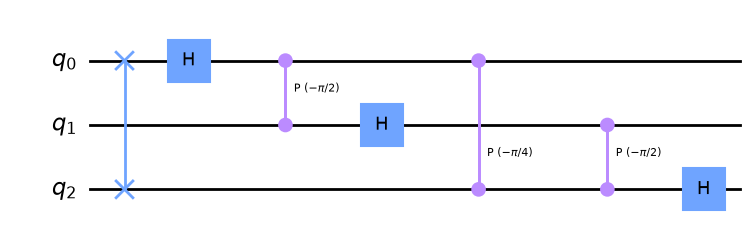

↑ QFT† on 3 qubits: the swap reverses the qubit order, then each qubit gets the controlled phases −π/2, −π/4 from the lower qubits and a Hadamard
inverse_qft(3) == QFTGate(3).inverse() ? True


In [2]:
def inverse_qft(n: int) -> QuantumCircuit:                 # type hints: `n: int` = n should be an int, `-> QuantumCircuit` = what the function returns (documentation only, Python does not enforce them)
    """
    Costruisce la QFT inversa per n qubit.

    La QFT trasforma |j⟩ → (1/√N) Σ_k e^(2πijk/N) |k⟩
    La QFT inversa fa l'operazione inversa.

    Args:
        n: Numero di qubit

    Returns:
        QuantumCircuit per QFT⁻¹
    """
    qc = QuantumCircuit(n, name=f'QFT†({n})')              # name= labels the box when this circuit is composed into a bigger one

    # Swap per invertire l'ordine dei bit: QFT = rotazioni poi swap, quindi QFT† = swap poi rotazioni coniugate
    for i in range(n // 2):                                # // = integer division: n//2 pairs (qubit i, qubit n-1-i)
        qc.swap(i, n - i - 1)

    # Hadamard e rotazioni controllate (angoli negativi per l'inversa), in ordine inverso rispetto alla QFT
    for j in range(n):                                     # qubit j: first the controlled phases from every lower qubit k < j ...
        for k in range(j):
            angle = -np.pi / (2 ** (j - k))                # -π/2, -π/4, ... : the complex conjugate of the QFT's +π/2^(j-k)
            qc.cp(angle, k, j)                             # cp(θ, control, target): controlled phase; symmetric, so control/target order does not matter
        qc.h(j)                                            # ... then a Hadamard (the QFT does "H then rotations": read backwards it is "rotations then H")

    return qc

# Visualizza QFT inversa per 3 qubit
print("QFT Inversa per 3 qubit:")
display(draw(inverse_qft(3))); print("↑ QFT† on 3 qubits: the swap reverses the qubit order, then each qubit gets the controlled phases −π/2, −π/4 from the lower qubits and a Hadamard")

# Check against Qiskit's own QFTGate: Operator(...) builds the 8×8 unitary matrix, .equiv() compares two unitaries up to a global phase
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import Operator
print("inverse_qft(3) == QFTGate(3).inverse() ?", Operator(inverse_qft(3)).equiv(Operator(QFTGate(3).inverse())))


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `def inverse_qft(n: int) -> QuantumCircuit:` | a typed signature: the annotations say what goes in and what comes out; they are hints for the reader and for tools, not checks at run time |
| swaps first, then `cp(-π/2^(j-k), k, j)` + `h(j)` | QFT = (H and +phases, from the top qubit down) followed by swaps; the inverse runs it backwards with conjugate angles. The original version had the swaps AFTER the rotations, which is QFT† with the bit order reversed — the T-gate test then read 001 only 43 % of the time; the order is fixed here and checked against `QFTGate(3).inverse()` |
| `-np.pi / (2 ** (j - k))` | the angle shrinks with the distance j−k between the qubits: −π/2 for neighbours, −π/4 two apart ... (−π/2^(j−k)) |
| `Operator(...).equiv(...)` | the 2ⁿ×2ⁿ matrix of a circuit, compared with another up to a global phase: the way to test that a hand-built circuit is what you think |
| `print(...); display(draw(...))` | the picture is shown with `display`, so the cell can keep printing after it |

</details>


### 3.2 Implementazione QPE con Gate Parametrici Nativi

Usiamo il gate **CP (Controlled-Phase)** che è nativo in Qiskit e supportato direttamente dall'hardware. Questo evita problemi di transpilazione e produce circuiti più efficienti.

In [3]:
def build_qpe_circuit(n_count: int, phase_angle: float,
                      prepare_eigenstate: bool = True) -> QuantumCircuit:   # `bool = True`: a typed parameter with a default value (optional argument)
    """
    Costruisce il circuito QPE usando gate parametrici nativi.

    Usa il gate P(θ) = diag(1, e^{iθ}) come unitario.
    L'autostato |1⟩ ha autovalore e^{iθ}, quindi fase φ = θ/(2π).

    Args:
        n_count: Numero di qubit di conteggio (precisione = 1/2^n_count)
        phase_angle: Angolo θ del gate P(θ)
                    - Per T-gate: θ = π/4, φ = 1/8
                    - Per S-gate: θ = π/2, φ = 1/4
                    - Per fase arbitraria φ: θ = 2πφ
        prepare_eigenstate: Se True, prepara |1⟩ come autostato

    Returns:
        Circuito QPE completo
    """
    # Registri
    count_reg = QuantumRegister(n_count, 'count')           # n counting qubits (qubit k has weight 2^k in the result)
    target_reg = QuantumRegister(1, 'target')               # the qubit that holds the eigenstate |ψ⟩ = |1⟩
    meas_reg = ClassicalRegister(n_count, 'meas')           # n classical bits: the measured integer m

    qc = QuantumCircuit(count_reg, target_reg, meas_reg)    # a circuit built from registers; count_reg[k] indexes a single qubit

    # ═══════════════════════════════════════════════════════════════
    # PASSO 1: Preparazione dell'autostato |1⟩
    # P(θ)|1⟩ = e^{iθ}|1⟩, quindi |1⟩ è autostato con fase θ/(2π)
    # ═══════════════════════════════════════════════════════════════
    if prepare_eigenstate:
        qc.x(target_reg[0])  # |0⟩ → |1⟩                    # without this the target stays in |0⟩, whose eigenphase is 0

    qc.barrier(label='Prep |1⟩')                            # barrier: a visual separator (and a fence the transpiler does not move gates across)

    # ═══════════════════════════════════════════════════════════════
    # PASSO 2: Hadamard su tutti i qubit di conteggio
    # |0...0⟩ → (1/√2ⁿ) Σ|k⟩
    # ═══════════════════════════════════════════════════════════════
    qc.h(count_reg)                                         # a gate applied to a whole register = one gate per qubit

    qc.barrier(label='H⊗n')

    # ═══════════════════════════════════════════════════════════════
    # PASSO 3: Controlled-P^(2^k) usando CP nativo
    #
    # P(θ)^m = P(mθ), quindi:
    # Controlled-P(θ)^(2^k) = CP(θ · 2^k)
    #
    # Questo è il cuore dell'algoritmo: "scrive" la fase nel
    # registro di conteggio attraverso interferenza quantistica
    # ═══════════════════════════════════════════════════════════════
    for k in range(n_count):
        # U^(2^k) = P(θ)^(2^k) = P(θ · 2^k)
        angle = phase_angle * (2 ** k)                      # 2^k repetitions of P(θ) = a single P(2^k θ): no need to repeat the gate
        qc.cp(angle, count_reg[k], target_reg[0])           # control = counting qubit k, target = eigenstate qubit; the phase "kicks back" onto the control

    qc.barrier(label='CP(θ·2^k)')

    # ═══════════════════════════════════════════════════════════════
    # PASSO 4: QFT Inversa
    # Trasforma lo stato di fase in una rappresentazione misurabile
    # ═══════════════════════════════════════════════════════════════
    qft_inv = inverse_qft(n_count)
    qc.compose(qft_inv, count_reg, inplace=True)           # compose(other, qubits, inplace=True): paste the QFT† circuit onto the counting register, modifying qc itself

    qc.barrier(label='QFT†')

    # ═══════════════════════════════════════════════════════════════
    # PASSO 5: Misura
    # Il risultato m ≈ 2^n · φ, quindi φ ≈ m/2^n
    # ═══════════════════════════════════════════════════════════════
    qc.measure(count_reg, meas_reg)                         # measure(qubits, bits): counting qubit k -> classical bit k; the target is NOT measured

    return qc


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumCircuit(count_reg, target_reg, meas_reg)` | a circuit over named registers; `count_reg[k]` picks one qubit, `qc.h(count_reg)` acts on all of them |
| `prepare_eigenstate: bool = True` | typed optional argument; with `False` the target stays in \|0⟩ (eigenphase 0) — used by the In-depth analysis to feed a superposition of eigenstates |
| `qc.cp(phase_angle * 2**k, count_reg[k], target_reg[0])` | controlled-U^(2^k) in ONE gate, because P(θ)^(2^k) = P(2^k θ); the eigenvalue e^{2πi·2^k φ} is kicked back as a phase on the \|1⟩ branch of counting qubit k |
| `qc.compose(qft_inv, count_reg, inplace=True)` | pastes the inverse QFT onto the counting qubits; `inplace=True` modifies `qc` instead of returning a copy |
| `qc.barrier(label=...)` | labelled separators between the five steps: they make the drawing readable and stop the transpiler from merging gates across them |
| `qc.measure(count_reg, meas_reg)` | register-wise measurement: bit k of the result has weight 2^k, so the integer m = Σ bit_k 2^k and φ̂ = m / 2ⁿ |

</details>


### 3.3 Esempio: Stima della fase del T-gate

Il **T-gate** è il gate di fase con $\theta = \pi/4$:

$$T = P(\pi/4) = \begin{pmatrix} 1 & 0 \\ 0 & e^{i\pi/4} \end{pmatrix}$$

Per l'autostato $|1\rangle$, la fase è:

$$\varphi = \frac{\theta}{2\pi} = \frac{\pi/4}{2\pi} = \frac{1}{8} = 0.125$$

In [4]:
# Costruiamo il circuito QPE per T-gate
n_counting_qubits = 3  # 3 bit → precisione 1/8                      # resolution 1/2^3: 1/8 is exactly on the grid
theta_t_gate = np.pi / 4  # T-gate                                   # T = P(π/4)

qpe_circuit = build_qpe_circuit(n_counting_qubits, theta_t_gate)     # 3 counting qubits + 1 target = 4 qubits, 3 classical bits

print(f"Circuito QPE per T-gate:")
print(f"  Qubit di conteggio: {n_counting_qubits}")
print(f"  Angolo θ: π/4 = {theta_t_gate:.4f} rad")                    # :.4f = 4 decimals
print(f"  Fase attesa: φ = θ/(2π) = 1/8 = 0.125")
print(f"  In binario con 3 bit: 0.001₂ = 1/8")
print(f"  Risultato atteso: 001 (decimale 1)")
print(f"")
print(f"  Profondità circuito: {qpe_circuit.depth()}")               # depth = number of layers of gates that cannot run in parallel (barriers excluded)
print(f"  Numero totale gate: {qpe_circuit.size()}")                 # size = total number of instructions (measurements included, barriers not)


Circuito QPE per T-gate:
  Qubit di conteggio: 3
  Angolo θ: π/4 = 0.7854 rad
  Fase attesa: φ = θ/(2π) = 1/8 = 0.125
  In binario con 3 bit: 0.001₂ = 1/8
  Risultato atteso: 001 (decimale 1)

  Profondità circuito: 12
  Numero totale gate: 17


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `n_counting_qubits = 3` | 3 bits of phase: outcomes m = 0..7, φ̂ = m/8; 1/8 is representable exactly, so the algorithm is exact here |
| `theta_t_gate = np.pi / 4` | the angle of T = P(π/4); the eigenphase of \|1⟩ is θ/2π = 1/8 |
| `.depth()`, `.size()` | two cost measures of a circuit: layers in time vs total gate count (12 and 17 here, before transpilation) |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The 3-qubit QPE of the T gate, step by step.** Target in $|1\rangle$, counting register $|000\rangle$; counting qubit $k$ has weight $2^k$, so $|x\rangle = |x_2 x_1 x_0\rangle$ with $x = 4x_2 + 2x_1 + x_0$.

*After $H^{\otimes 3}$:* $\dfrac{1}{\sqrt 8}\sum_{x=0}^{7}|x\rangle|1\rangle$.

*Controlled phases.* $CP(\tfrac{\pi}{4}\,2^k)$ between counting qubit $k$ and the target multiplies the branch $|x\rangle|1\rangle$ by $e^{i\pi x_k 2^k/4}$ (nothing happens when $x_k = 0$: the phase is "kicked back" onto the control). Multiplying the three factors,

$$e^{i\pi (x_0 + 2x_1 + 4x_2)/4} = e^{i\pi x/4} = e^{2\pi i\,x\,\varphi}, \qquad \varphi = \tfrac18 ,$$

so the counting register becomes $\dfrac{1}{\sqrt 8}\sum_x e^{2\pi i x/8}|x\rangle$: the phases on $|0\rangle,\dots,|7\rangle$ are $0, 45^\circ, 90^\circ, \dots, 315^\circ$ — exactly $\mathrm{QFT}|1\rangle$, the Fourier basis state with $m = 1$.

*Inverse QFT.* $\mathrm{QFT}^{-1}\,\mathrm{QFT}|1\rangle = |1\rangle = |001\rangle$ (qubit 0 = 1). The measurement reads $m = 1$ with probability $1$ and $\hat\varphi = m/2^3 = 0.125$.

*In general:* for $\varphi = m/2^n$ exactly, the state after the controlled phases is exactly $\mathrm{QFT}|m\rangle$ and QPE returns $m$ with certainty — the ideal simulation below prints `001` with probability `1.0000` (4096 shots out of 4096); on a noisy backend a few percent leak to the other bitstrings.

</details>


Circuito QPE completo:


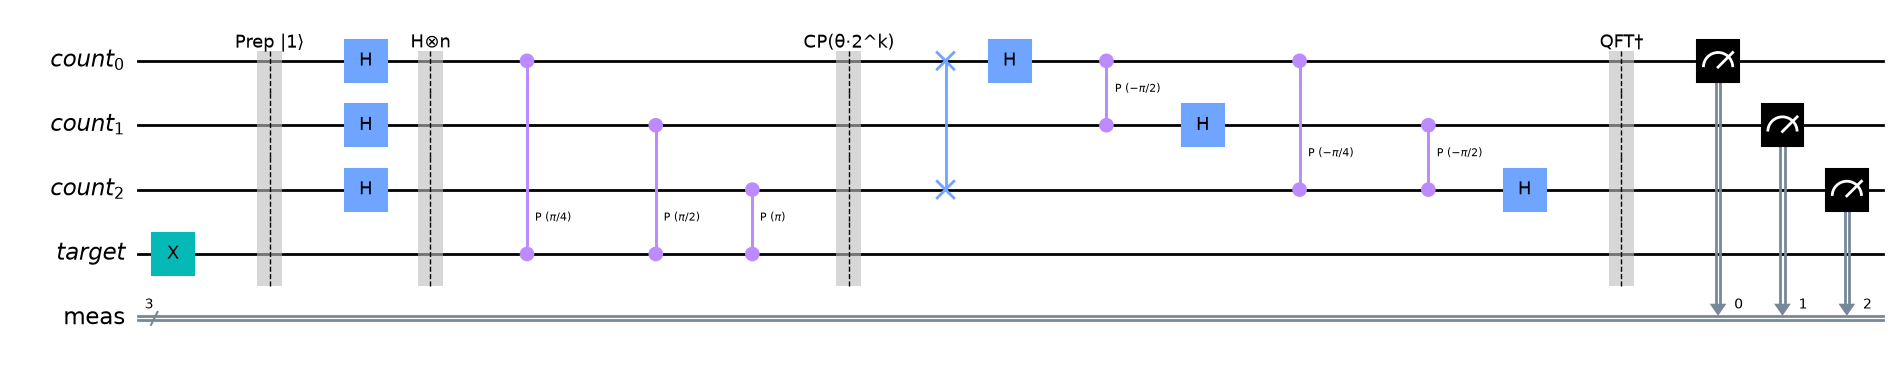

↑ the 3-qubit QPE of T: X prepares |1⟩ on the target, H⊗3 on the counting register, CP(π/4·2^k) controlled by counting qubit k, then QFT† (swap, controlled phases, H) and the measurement of the counting register only


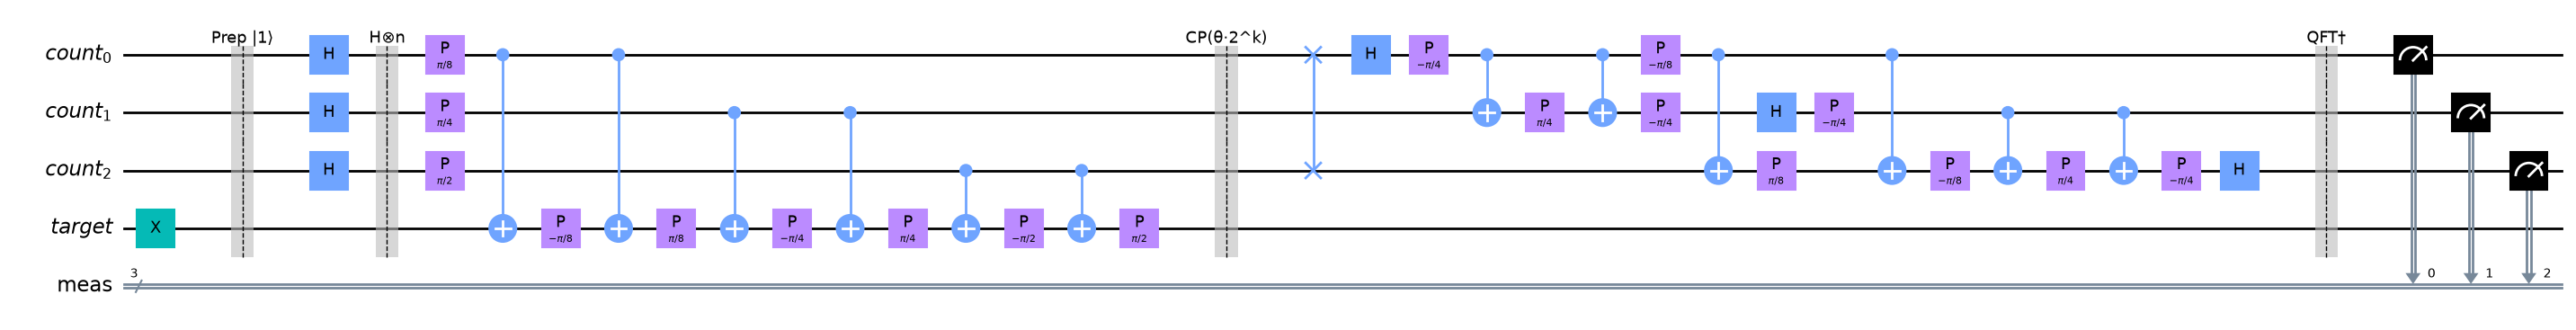

↑ the same circuit with every CP expanded into CNOTs and single-qubit phases — {'p': 18, 'cx': 12, 'h': 6, 'barrier': 4, 'measure': 3, 'x': 1, 'swap': 1}: this is roughly what a device without a native controlled-phase gate must run


In [5]:
# Visualizza il circuito
print("Circuito QPE completo:")
display(draw(qpe_circuit)); print("↑ the 3-qubit QPE of T: X prepares |1⟩ on the target, H⊗3 on the counting register, CP(π/4·2^k) controlled by counting qubit k, then QFT† (swap, controlled phases, H) and the measurement of the counting register only")

expanded = qpe_circuit.decompose(gates_to_decompose=['cp'])          # expand only the CP gates one level (each CP = 2 CNOT + 3 P)
display(draw(expanded)); print(f"↑ the same circuit with every CP expanded into CNOTs and single-qubit phases — {dict(expanded.count_ops())}: this is roughly what a device without a native controlled-phase gate must run")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `display(draw(qpe_circuit))` | the full circuit in one row; the labelled barriers separate the five steps of `build_qpe_circuit` |
| `.decompose(gates_to_decompose=['cp'])` | opens only the named gate type one level: a CP(θ) is P(θ/2) on the control, CNOT, P(−θ/2), CNOT, P(θ/2) — 2 two-qubit gates each |
| `dict(expanded.count_ops())` | gate census of the expanded circuit: 6 CP (3 in the kick-back step, 3 in QFT†) become 12 CNOTs, the dominant cost on hardware |

</details>


<a id='simulator'></a>
## 4. 🖥️ Esecuzione su Simulatore

In [6]:
def run_qpe_simulation(circuit: QuantumCircuit, shots: int = 4096) -> dict:   # `shots: int = 4096` typed parameter with default; `-> dict` return type
    """
    Esegue QPE su simulatore ideale.

    Args:
        circuit: Circuito QPE
        shots: Numero di misure

    Returns:
        Dizionario con risultati e analisi
    """
    simulator = AerSimulator()                                       # ideal (noise-free) local simulator
    sampler = AerSampler()                                           # Sampler primitive: returns the counts of each classical register

    pm = generate_preset_pass_manager(optimization_level=1, backend=simulator)   # transpiler for this backend; level 1 = light optimisation
    transpiled = pm.run(circuit)                                     # rewrite the circuit in the simulator's gate set (here almost unchanged)

    job = sampler.run([transpiled], shots=shots)                     # the Sampler takes a LIST of circuits (one "pub" each)
    result = job.result()
    counts = result[0].data.meas.get_counts()                        # result[0] = first pub; .data.meas = the register named 'meas'; -> {'bitstring': count}

    return {                                                         # a dict is a convenient way to return several named values
        'counts': counts,
        'shots': shots,
        'transpiled_depth': transpiled.depth(),
        'transpiled_ops': dict(transpiled.count_ops())               # {gate name: how many}: what the backend actually executed
    }

def analyze_qpe_results(counts: dict, n_count: int, true_phase: float = None):   # `float = None`: an optional argument (strictly `Optional[float]`); no return annotation here
    """
    Analizza e interpreta i risultati della QPE.

    Args:
        counts: Conteggi delle misure
        n_count: Numero di qubit di conteggio
        true_phase: Fase vera (se nota) per calcolare l'errore

    Returns:
        (fase_stimata, probabilità)
    """
    print("═" * 60)                                                   # a string times an int repeats it
    print("ANALISI RISULTATI QPE")
    print("═" * 60)

    total_shots = sum(counts.values())                                # .values() = the counts only; their sum = number of shots
    sorted_counts = sorted(counts.items(), key=lambda x: -x[1])       # .items() = (bitstring, count) pairs; sort by count, descending (the minus sign)

    print(f"\n{'Binario':<12} {'Decimale':<10} {'Fase φ':<12} {'Conteggi':<10} {'Prob':<8}")   # f-string format `:<12` = left-aligned in a 12-character column
    print("-" * 60)

    estimated_phases = []
    probabilities = []

    for bitstring, count in sorted_counts[:8]:                       # the 8 most frequent outcomes; the pair is unpacked into two loop variables
        decimal = int(bitstring, 2)                                   # int(string, 2): read the bitstring as a base-2 integer m
        phase = decimal / (2 ** n_count)                              # φ̂ = m / 2ⁿ
        prob = count / total_shots

        estimated_phases.append(phase)
        probabilities.append(prob)

        marker = " ← BEST" if prob > 0.5 else ""                      # conditional expression: value_if_true if condition else value_if_false
        print(f"{bitstring:<12} {decimal:<10} {phase:<12.6f} {count:<10} {prob:<8.4f}{marker}")   # `:<12.6f` = left-aligned, 6 decimals

    print("\n" + "─" * 60)
    print(f"Fase stimata (modo): {estimated_phases[0]:.6f}")          # [0] = the most frequent outcome = the mode of the distribution

    if true_phase is not None:                                        # `is not None` (not `if true_phase:`): a true phase of 0 must still count as given
        error = abs(estimated_phases[0] - true_phase)
        print(f"Fase vera: {true_phase:.6f}")
        print(f"Errore assoluto: {error:.6f}")
        if true_phase != 0:
            print(f"Errore relativo: {100*error/true_phase:.2f}%")

    return estimated_phases[0], probabilities[0]                      # two values -> a tuple; the caller unpacks it: `phase, prob = analyze_qpe_results(...)`


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `def f(x: T = default) -> R:` | the typed-Python idiom used throughout the notebook: parameter annotations, defaults, and the return type after `->`; Python ignores them at run time, readers and editors do not |
| `generate_preset_pass_manager(1, backend)` → `pm.run(circuit)` | the Qiskit 2.x transpilation: a pass manager built for the backend, then applied to the circuit |
| `sampler.run([transpiled], shots=...)` → `result[0].data.meas.get_counts()` | SamplerV2 interface: a list of circuits in, one result per circuit out; the counts are stored under the classical register's NAME (`meas`) |
| `return {'counts': ..., 'transpiled_ops': ...}` | several results packed in a dict; the caller reads `results['counts']` |
| `sorted(counts.items(), key=lambda x: -x[1])` | sort the (bitstring, count) pairs by count, largest first; `lambda` = a one-line anonymous function |
| `int(bitstring, 2) / 2 ** n_count` | the decoding rule of QPE: the bitstring is the integer m, the phase estimate is m / 2ⁿ |

</details>


In [7]:
# Esegui simulazione per T-gate
print("Esecuzione QPE per T-gate (φ = 1/8 = 0.125)...\n")

results = run_qpe_simulation(qpe_circuit, shots=4096)                # dict with 'counts', 'shots', 'transpiled_depth', 'transpiled_ops'
estimated_phase, prob = analyze_qpe_results(results['counts'], n_counting_qubits, true_phase=0.125)   # unpack the returned (phase, probability) tuple

print(f"\nProfondità circuito transpilato: {results['transpiled_depth']}")
print(f"Gate del circuito transpilato: {results['transpiled_ops']}")   # which gates, and how many, the backend executed


Esecuzione QPE per T-gate (φ = 1/8 = 0.125)...



════════════════════════════════════════════════════════════
ANALISI RISULTATI QPE
════════════════════════════════════════════════════════════

Binario      Decimale   Fase φ       Conteggi   Prob    
------------------------------------------------------------
001          1          0.125000     4096       1.0000   ← BEST

────────────────────────────────────────────────────────────
Fase stimata (modo): 0.125000
Fase vera: 0.125000
Errore assoluto: 0.000000
Errore relativo: 0.00%

Profondità circuito transpilato: 12
Gate del circuito transpilato: {'h': 6, 'cp': 6, 'barrier': 4, 'measure': 3, 'x': 1, 'swap': 1}


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `results['counts']` | the measurement histogram as a dict; the table lists its outcomes from the most to the least frequent |
| `001` → m = 1 → φ̂ = 1/8 | the decoding: 1/8 is exactly representable with 3 bits, so the ideal simulator puts every shot on 001 (probability 1.0000, 'BEST') |
| `transpiled_ops` | the gate census after transpilation; compare it with the IQM edition, where the same circuit becomes r (PRX) and cz gates only |

</details>


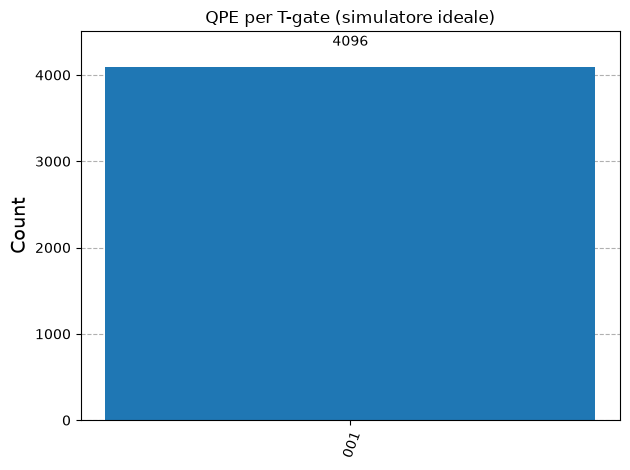

↑ the counting register reads 001 (m = 1 → φ = 1/8); any other bar is noise, not QPE: 1/8 is exact with 3 bits


In [8]:
# Istogramma dei risultati
display(plot_histogram(results['counts'], title='QPE per T-gate (simulatore ideale)')); print("↑ the counting register reads 001 (m = 1 → φ = 1/8); any other bar is noise, not QPE: 1/8 is exact with 3 bits")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plot_histogram(counts, title=...)` | bar chart of the counts; the bitstrings are sorted, the heights are probabilities |
| `display(...); print("↑ ...")` | the figure is a return value: `display` shows it explicitly so that the caption can follow in the same cell |

</details>


### 4.1 Interpretazione dei Risultati

**Risultato**: Misuriamo `001` con probabilità ~100%

**Decodifica**:
- Binario `001` = decimale 1
- Fase: $\varphi = 1/2^3 = 1/8 = 0.125$

**Perché funziona perfettamente?**

La fase $\varphi = 1/8$ è **esattamente rappresentabile** con 3 bit:
$$\varphi = 0.125_{10} = 0.001_2$$

Quando la fase è esattamente rappresentabile, la QPE dà il risultato corretto con probabilità 1.

### 4.2 Test con Fase Non Rappresentabile

Cosa succede quando $\varphi$ non è esattamente rappresentabile? Testiamo con $\varphi = 1/3$.

In [9]:
# QPE per φ = 1/3 (non rappresentabile esattamente in binario)
phi_target = 1/3
theta_target = 2 * np.pi * phi_target  # θ = 2πφ                      # the P(θ) whose |1⟩ eigenphase is 1/3
n_qubits_test = 4                                                     # grid of 16 values: 1/3 falls between 5/16 and 6/16

qpe_test = build_qpe_circuit(n_qubits_test, theta_target)
results_test = run_qpe_simulation(qpe_test, shots=4096)

print(f"Test QPE con φ = 1/3 ≈ 0.3333...")
print(f"")
print(f"Con {n_qubits_test} qubit, i valori rappresentabili più vicini sono:")
print(f"  5/16 = 0.3125 (binario: 0101) - distanza: {abs(5/16 - 1/3):.4f}")
print(f"  6/16 = 0.3750 (binario: 0110) - distanza: {abs(6/16 - 1/3):.4f}")
print()

phase_test, prob_test = analyze_qpe_results(results_test['counts'], n_qubits_test, true_phase=phi_target)   # mode and its probability (≈ 0.685 for 0101)


Test QPE con φ = 1/3 ≈ 0.3333...

Con 4 qubit, i valori rappresentabili più vicini sono:
  5/16 = 0.3125 (binario: 0101) - distanza: 0.0208
  6/16 = 0.3750 (binario: 0110) - distanza: 0.0417

════════════════════════════════════════════════════════════
ANALISI RISULTATI QPE
════════════════════════════════════════════════════════════

Binario      Decimale   Fase φ       Conteggi   Prob    
------------------------------------------------------------
0101         5          0.312500     2816       0.6875   ← BEST
0110         6          0.375000     730        0.1782  
0100         4          0.250000     168        0.0410  
0111         7          0.437500     102        0.0249  
1000         8          0.500000     51         0.0125  
0011         3          0.187500     49         0.0120  
0010         2          0.125000     38         0.0093  
1001         9          0.562500     24         0.0059  

────────────────────────────────────────────────────────────
Fase stimata (modo):

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `theta_target = 2 * np.pi * phi_target` | any phase φ can be tested: P(2πφ) has eigenphase φ on \|1⟩ |
| `n_qubits_test = 4` | 16 grid points: 1/3 = 0.0101010101...₂ is not one of them, so the outcome is spread |
| `0101` with ≈ 0.68, `0110` with ≈ 0.17 | the two nearest grid values take ≈ 86 % of the shots (bound: 8/π² ≈ 0.81); the nearest one alone ≥ 4/π² ≈ 0.405 — see the box below |
| `phase_test, prob_test = ...` | the tuple returned by the analysis is kept in two variables instead of being echoed as the cell's output |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The spread for $\varphi = 1/3$.** After the controlled phases the counting register is $\frac{1}{2^{n/2}}\sum_x e^{2\pi i x\varphi}|x\rangle$; the inverse QFT sends it to $\sum_m c_m |m\rangle$ with (geometric sum)

$$P(m) = |c_m|^2 = \frac{1}{2^{2n}}\left|\frac{\sin \pi\delta_m}{\sin(\pi\delta_m/2^n)}\right|^2, \qquad \delta_m = 2^n\varphi - m .$$

With $n = 4$: $2^n\varphi = 16/3 = 5.\overline{3}$.

*Nearest value* $m = 5$ ($\hat\varphi = 5/16 = 0.3125$): $\delta = 1/3$,
$P(5) = \dfrac{1}{256}\,\dfrac{\sin^2(\pi/3)}{\sin^2(\pi/48)} = \dfrac{0.75}{256 \times 0.004277} \approx 0.685 .$

*Second nearest* $m = 6$ ($6/16 = 0.375$): $\delta = -2/3$,
$P(6) = \dfrac{1}{256}\,\dfrac{\sin^2(2\pi/3)}{\sin^2(\pi/24)} = \dfrac{0.75}{256 \times 0.01704} \approx 0.172 .$

Together $P(5) + P(6) \approx 0.857$: the two outcomes bracketing $\varphi$ carry more than $8/\pi^2 \approx 0.81$ of the probability (the general bound for the pair, whatever $\varphi$), and the nearest one alone more than $4/\pi^2 \approx 0.405$ — this is the $P_{\rm success}$ bound of Section 2.3. The remaining $\approx 14\,\%$ decays like $1/\delta^2$ on the other 14 values. The table above prints `0101` with probability $\approx 0.68$ (ideal simulator) and the error $|0.3125 - 0.3333| = 0.0208 < 1/2^{4+1}$.

</details>


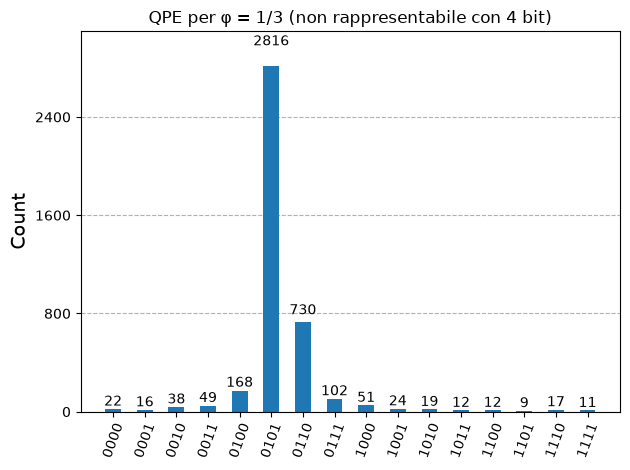

↑ φ = 1/3 is not a 4-bit fraction: the weight spreads over the two nearest grid values 0101 (5/16) and 0110 (6/16) — ≈ 68 % and ≈ 17 % on an ideal device — with tails decaying like 1/δ² on the others (plus device noise on a real backend)


In [10]:
display(plot_histogram(results_test['counts'],
               title=f'QPE per φ = 1/3 (non rappresentabile con {n_qubits_test} bit)')); print("↑ φ = 1/3 is not a 4-bit fraction: the weight spreads over the two nearest grid values 0101 (5/16) and 0110 (6/16) — ≈ 68 % and ≈ 17 % on an ideal device — with tails decaying like 1/δ² on the others (plus device noise on a real backend)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plot_histogram(..., title=f'... {n_qubits_test} ...')` | an f-string inside the title: the figure labels itself from the variables |
| the shape of the histogram | one dominant bar flanked by a smaller neighbour and small tails: the signature of a phase that is not on the grid (compare with the single bar of the T gate) |

</details>


### 4.3 Precisione vs Numero di Qubit

In [11]:
# Studio sistematico della precisione
phi_target = 1/3
theta_target = 2 * np.pi * phi_target
n_qubit_range = [2, 3, 4, 5, 6, 7]                                    # from 4 to 128 grid points

print("═" * 70)
print(f"ANALISI PRECISIONE QPE per φ = {phi_target:.6f}")
print("═" * 70)
print(f"\n{'N qubit':<10} {'Δφ teorico':<15} {'φ stimata':<15} {'Errore':<15} {'P(modo)':<12}")
print("-" * 70)

results_precision = []                                                # list of dicts, one row per n

for n in n_qubit_range:
    qpe = build_qpe_circuit(n, theta_target)                          # n counting qubits + 1 target
    result = run_qpe_simulation(qpe, shots=2048)
    counts = result['counts']

    top_result = max(counts.items(), key=lambda x: x[1])              # the (bitstring, count) pair with the largest count = the mode
    estimated = int(top_result[0], 2) / (2**n)                        # decode the mode: m / 2ⁿ
    error = abs(estimated - phi_target)
    prob = top_result[1] / sum(counts.values())                       # probability of the mode
    precision = 1 / (2**n)                                            # the grid spacing (resolution) Δφ

    results_precision.append({                                        # one dict per row, read back by the plot below
        'n': n,
        'precision': precision,
        'estimated': estimated,
        'error': error,
        'prob': prob
    })

    print(f"{n:<10} {precision:<15.6f} {estimated:<15.6f} {error:<15.6f} {prob:<12.4f}")


══════════════════════════════════════════════════════════════════════
ANALISI PRECISIONE QPE per φ = 0.333333
══════════════════════════════════════════════════════════════════════

N qubit    Δφ teorico      φ stimata       Errore          P(modo)     
----------------------------------------------------------------------


2          0.250000        0.250000        0.083333        0.7163      


3          0.125000        0.375000        0.041667        0.6826      


4          0.062500        0.312500        0.020833        0.6655      
5          0.031250        0.343750        0.010417        0.6924      


6          0.015625        0.328125        0.005208        0.6831      
7          0.007812        0.335938        0.002604        0.6812      


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `for n in n_qubit_range:` … `build_qpe_circuit(n, theta_target)` | the same experiment at six resolutions; the circuit grows by one counting qubit (and n more CP gates) each step |
| `max(counts.items(), key=lambda x: x[1])` | the mode of the histogram: `max` over pairs, compared by their second element (the count) |
| `error` vs `precision` | the mode is always the nearest grid point here, so the error is ≤ Δφ/2 = 1/2ⁿ⁺¹ and halves with every extra qubit |
| `results_precision.append({...})` | a list of dicts = a small table in pure Python; the next cell extracts its columns with list comprehensions |
| `P(modo)` ≈ 0.68–0.7 for n ≥ 3 | the probability of the nearest value does NOT improve with n: it depends only on the fractional part of 2ⁿφ (for 1/3 it alternates between ≈ 0.69 and ≈ 0.68), always above 4/π² ≈ 0.405 |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Resolution and number of qubits.** With $t$ counting qubits the outcomes lie on the grid $m/2^t$, spacing $\Delta\varphi = 1/2^t$; the nearest grid point is within $1/2^{t+1}$ of $\varphi$. For $\varphi = 1/3$:

| $t$ | $2^t\varphi$ | nearest $m$ | $\hat\varphi = m/2^t$ | error | $1/2^{t+1}$ |
|---|---|---|---|---|---|
| 2 | 1.33 | 1 | 0.25 | 0.0833 | 0.125 |
| 3 | 2.67 | 3 | 0.375 | 0.0417 | 0.0625 |
| 4 | 5.33 | 5 | 0.3125 | 0.0208 | 0.03125 |
| 5 | 10.67 | 11 | 0.34375 | 0.0104 | 0.0156 |
| 6 | 21.33 | 21 | 0.328125 | 0.0052 | 0.0078 |
| 7 | 42.67 | 43 | 0.3359375 | 0.0026 | 0.0039 |

These are the `Errore` values printed above by the ideal simulator — they halve with each extra qubit, as $1/2^t$ does.

**How many qubits for a given precision?** To resolve $\varphi$ to within $\epsilon$ you need $1/2^{t} \le \epsilon$, i.e. $t = \lceil \log_2(1/\epsilon) \rceil$: for $\epsilon = 0.01$, $t = 7$ ($1/128 = 0.0078$). That guarantees the *nearest* outcome is good enough, but it comes out only with probability $\ge 4/\pi^2$. To get an estimate accurate to $p$ bits with probability at least $1-\delta$, Nielsen & Chuang (eq. 5.35) prescribe

$$t = p + \left\lceil \log_2\!\left(2 + \frac{1}{2\delta}\right)\right\rceil ,$$

so $p = 7$ bits with $\delta = 0.1$ costs $7 + \lceil\log_2 7\rceil = 10$ counting qubits: the extra three qubits push the tails of the spread below one unit of the 7-bit grid. The author's Exercise 2 ($\varphi = \sqrt 2/4$, error $< 0.01$) is solved this way in the In-depth analysis.

</details>


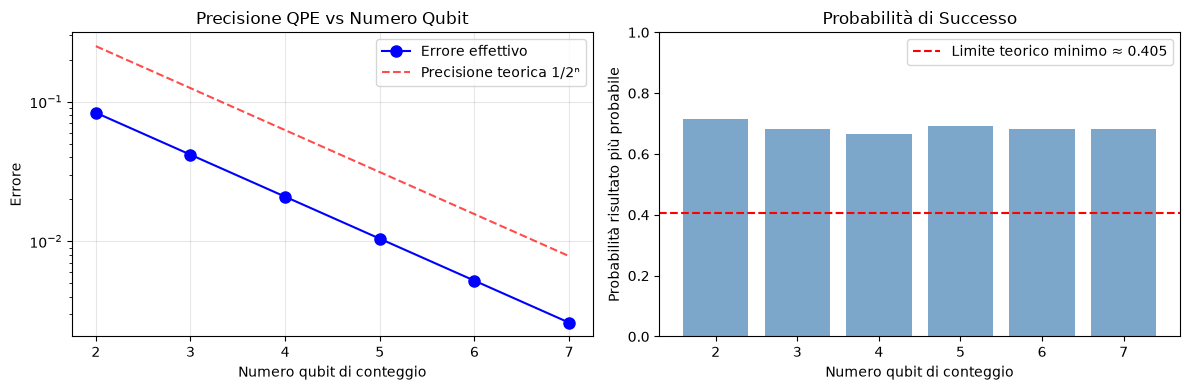

↑ left: the error of the mode (blue) halves with every counting qubit and stays below the resolution 1/2ⁿ (red); right: the probability of the mode does not grow with n — it stays near the 0.68 of the φ = 1/3 spread, above the 4/π² ≈ 0.405 bound


In [12]:
# Grafico precisione
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))               # one figure, two panels side by side (unpacked into ax1, ax2)

ns = [r['n'] for r in results_precision]                             # list comprehensions: pull one column out of the list of dicts
errors = [r['error'] for r in results_precision]
precisions = [r['precision'] for r in results_precision]
probs = [r['prob'] for r in results_precision]

ax1.semilogy(ns, errors, 'bo-', label='Errore effettivo', markersize=8)     # log scale on y: a halving per qubit is a straight line
ax1.semilogy(ns, precisions, 'r--', label='Precisione teorica 1/2ⁿ', alpha=0.7)
ax1.set_xlabel('Numero qubit di conteggio')
ax1.set_ylabel('Errore')
ax1.set_title('Precisione QPE vs Numero Qubit')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.bar(ns, probs, color='steelblue', alpha=0.7)
ax2.axhline(y=4/np.pi**2, color='r', linestyle='--',
            label=f'Limite teorico minimo ≈ {4/np.pi**2:.3f}')          # horizontal reference line at 4/π²
ax2.set_xlabel('Numero qubit di conteggio')
ax2.set_ylabel('Probabilità risultato più probabile')
ax2.set_title('Probabilità di Successo')
ax2.legend()
ax2.set_ylim(0, 1)

plt.tight_layout()
plt.show()
print("↑ left: the error of the mode (blue) halves with every counting qubit and stays below the resolution 1/2ⁿ (red); right: the probability of the mode does not grow with n — it stays near the 0.68 of the φ = 1/3 spread, above the 4/π² ≈ 0.405 bound")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `[r['error'] for r in results_precision]` | list comprehension: build the y-values of a curve from one key of every dict |
| `ax1.semilogy(...)` | logarithmic y axis: an exponential decrease (1/2ⁿ) becomes a straight line, easy to compare with the data |
| `ax2.axhline(y=4/np.pi**2, ...)` | the theoretical lower bound on the probability of the nearest outcome, drawn as a horizontal dashed line |

</details>


<a id='hardware'></a>
## 5. 🔬 Esecuzione su Hardware Reale IBM

L'esecuzione su hardware reale introduce errori:
- **Decoerenza**: T1 (rilassamento) e T2 (defasamento)
- **Errori di gate**: ~0.1% per 1-qubit, ~1% per 2-qubit
- **Errori di misura**: ~1-5%
- **Crosstalk**: interferenza tra qubit

In [13]:
def run_qpe_hardware(circuit: QuantumCircuit, shots: int = 4096,
                     backend_name: str = None) -> dict:               # `str = None`: optional backend name; None = let the service pick
    """
    Esegue QPE su hardware IBM Quantum.
    """
    if not IBM_AVAILABLE:                                             # guard 1: the package is not installed -> message, no crash
        print("⚠ IBM Runtime non disponibile")
        print("  Installa: pip install qiskit-ibm-runtime")
        return None

    try:
        service = QiskitRuntimeService()                              # loads the saved account; raises if none was saved ...
    except Exception as e:                                            # guard 2: ... which is caught here -> message, return None
        print(f"⚠ Errore connessione: {e}")
        print("  Configura con:")
        print("  QiskitRuntimeService.save_account(channel='ibm_quantum', token='TOKEN')")
        return None

    if backend_name:
        backend = service.backend(backend_name)                       # a specific device by name ...
    else:
        backend = service.least_busy(operational=True, simulator=False)   # ... or the real device with the shortest queue

    print(f"Backend: {backend.name}")
    print(f"  Qubit: {backend.num_qubits}")
    print(f"  Jobs in coda: {backend.status().pending_jobs}")

    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)   # level 3 = heaviest optimisation: worth it for a real device
    transpiled = pm.run(circuit)                                      # maps onto physical qubits and the native gates (ECR/RZ/SX/X on IBM)

    print(f"\nCircuito transpilato:")
    print(f"  Profondità: {circuit.depth()} → {transpiled.depth()}")  # the depth grows: SWAPs for connectivity, CP -> several native gates

    print(f"\nInvio job...")
    sampler = IBMSampler(backend)                                     # the cloud Sampler bound to this device
    job = sampler.run([transpiled], shots=shots)                      # asynchronous: returns immediately with a job id
    print(f"Job ID: {job.job_id()}")

    result = job.result()                                             # blocks until the job has run (queue time included)
    counts = result[0].data.meas.get_counts()                         # same result interface as the local Sampler

    return {
        'counts': counts,
        'backend': backend.name,
        'job_id': job.job_id()
    }


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `if not IBM_AVAILABLE: ... return None` | first guard: without the package the function prints how to install it and returns None |
| `try: service = QiskitRuntimeService() except Exception as e:` | second guard: without a saved account the constructor raises; the message is printed and None is returned — so the function never crashes the notebook |
| `service.least_busy(operational=True, simulator=False)` | pick the real device with the shortest queue; `backend_name` overrides it |
| `generate_preset_pass_manager(optimization_level=3, backend=backend)` | transpile for the real chip: physical qubits, native gates, SWAPs for the heavy-hex connectivity |
| `sampler.run(...)` → `job.job_id()` → `job.result()` | submission is asynchronous; `.result()` waits for the queue, then the counts come back under the register name `meas` |

</details>


In [14]:
# Per eseguire su hardware reale, decommenta:                        # left commented on purpose: with a saved account it would submit a real job and wait in the queue
# hw_results = run_qpe_hardware(qpe_circuit, shots=4096)
# if hw_results:                                                      # None (no account / no package) is falsy: the analysis is skipped
#     analyze_qpe_results(hw_results['counts'], n_counting_qubits, true_phase=0.125)
#     plot_histogram(hw_results['counts'], title=f"QPE su {hw_results['backend']}")

print("Per eseguire su hardware IBM Quantum:")
print("1. Installa: pip install qiskit-ibm-runtime")
print("2. Configura credenziali")
print("3. Decommenta il codice sopra")


Per eseguire su hardware IBM Quantum:
1. Installa: pip install qiskit-ibm-runtime
2. Configura credenziali
3. Decommenta il codice sopra


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| the commented call | the real-hardware run is opt-in: uncomment it only with an IBM account and QPU time; without an account `run_qpe_hardware` prints a connection message and returns None instead of raising |
| `if hw_results:` | None is falsy in Python, so the analysis and the histogram run only when a result actually came back |
| `print(...)` × 4 | what this cell does without an account: a checklist, no job |

</details>


### 5.1 Simulazione con Rumore Realistico

In [15]:
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error   # Aer's noise toolbox

def create_noise_model(p1q: float = 0.001, p2q: float = 0.01,
                       t1: float = 100e3, t2: float = 80e3) -> NoiseModel:   # times in ns: 100e3 ns = 100 μs
    """
    Crea un modello di rumore realistico.

    Args:
        p1q: Errore gate 1-qubit (~0.1%)
        p2q: Errore gate 2-qubit (~1%)
        t1: Tempo T1 in ns (~100 μs)
        t2: Tempo T2 in ns (~80 μs)
    """
    noise = NoiseModel()                                              # empty model; errors are attached gate by gate

    # Errori depolarizzanti
    err_1q = depolarizing_error(p1q, 1)                               # with probability p1q the qubit is replaced by the maximally mixed state
    err_2q = depolarizing_error(p2q, 2)                               # the 2-qubit version (acts on both qubits of the gate)

    # Errori termici
    err_t1 = thermal_relaxation_error(t1, t2, 50)  # 50 ns per gate 1q      # T1/T2 decay during a 50 ns single-qubit gate
    err_t2 = thermal_relaxation_error(t1, t2, 300).tensor(
             thermal_relaxation_error(t1, t2, 300))  # 300 ns per gate 2q   # .tensor: independent relaxation on each of the two qubits

    noise.add_all_qubit_quantum_error(err_1q.compose(err_t1), ['h', 'p', 'x'])   # .compose = one error after the other; applied after every h, p, x on any qubit
    noise.add_all_qubit_quantum_error(err_2q.compose(err_t2), ['cx', 'cp'])      # and the 2-qubit error after every cx / cp

    return noise

def run_qpe_noisy(circuit: QuantumCircuit, noise: NoiseModel,
                  shots: int = 4096) -> dict:
    """Esegue QPE con rumore."""
    sim_noisy = AerSimulator(noise_model=noise)                       # the same simulator, now applying the noise model after each gate
    sampler = AerSampler()
    sampler._backend = sim_noisy                                      # attach the noisy simulator to the Sampler (a private attribute, hence the underscore: it works, but it is not public API)

    pm = generate_preset_pass_manager(optimization_level=1, backend=sim_noisy)
    transpiled = pm.run(circuit)                                      # the noise model names h, p, x, cx, cp: these must survive transpilation (they do, Aer supports them natively)

    job = sampler.run([transpiled], shots=shots)
    counts = job.result()[0].data.meas.get_counts()

    return {'counts': counts}


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `depolarizing_error(p, n)` | with probability p the n-qubit state is replaced by random noise; p1q ≈ 0.1 % and p2q ≈ 1 % are typical device numbers |
| `thermal_relaxation_error(T1, T2, t_gate)` | amplitude damping (T1) and dephasing (T2) accumulated during one gate of duration t_gate; `.tensor` makes the 2-qubit version |
| `err_1q.compose(err_t1)` | two error channels applied in sequence after the gate: depolarising, then relaxation |
| `add_all_qubit_quantum_error(err, ['h', 'p', 'x'])` | the error is attached to these gate NAMES on every qubit — gates not in the list (e.g. `swap`) run noise-free in this model |
| `AerSimulator(noise_model=noise)` / `sampler._backend = sim_noisy` | the noisy simulator, handed to the Sampler through a private attribute; the rest of the pipeline is identical to the ideal run |

</details>


In [16]:
# Confronto ideale vs rumoroso
print("CONFRONTO: Simulatore Ideale vs Rumoroso")
print("=" * 60)

noise = create_noise_model(p1q=0.001, p2q=0.01)                       # keyword arguments: the other two parameters keep their defaults

print("\n[1] Simulatore IDEALE:")
ideal_res = run_qpe_simulation(qpe_circuit, shots=4096)
ideal_phase, ideal_prob = analyze_qpe_results(
    ideal_res['counts'], n_counting_qubits, true_phase=0.125)

print("\n[2] Simulatore con RUMORE:")
noisy_res = run_qpe_noisy(qpe_circuit, noise, shots=4096)
noisy_phase, noisy_prob = analyze_qpe_results(
    noisy_res['counts'], n_counting_qubits, true_phase=0.125)         # same mode (001), a few percent of the shots leak to other bitstrings


CONFRONTO: Simulatore Ideale vs Rumoroso

[1] Simulatore IDEALE:
════════════════════════════════════════════════════════════
ANALISI RISULTATI QPE
════════════════════════════════════════════════════════════

Binario      Decimale   Fase φ       Conteggi   Prob    
------------------------------------------------------------
001          1          0.125000     4096       1.0000   ← BEST

────────────────────────────────────────────────────────────
Fase stimata (modo): 0.125000
Fase vera: 0.125000
Errore assoluto: 0.000000
Errore relativo: 0.00%

[2] Simulatore con RUMORE:
════════════════════════════════════════════════════════════
ANALISI RISULTATI QPE
════════════════════════════════════════════════════════════

Binario      Decimale   Fase φ       Conteggi   Prob    
------------------------------------------------------------
001          1          0.125000     3696       0.9023   ← BEST
000          0          0.000000     109        0.0266  
101          5          0.625000   

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `create_noise_model(p1q=0.001, p2q=0.01)` | keyword arguments by name; t1 and t2 keep their defaults (100 μs, 80 μs) |
| `run_qpe_simulation` vs `run_qpe_noisy` | the SAME circuit through the ideal and the noisy simulator: only the backend differs |
| `ideal_prob`, `noisy_prob` | the probability of the mode in the two cases: 1.000 ideal, ≈ 0.90 with noise — 6 two-qubit gates at 1 % plus relaxation on every gate cost about a tenth of the shots |

</details>


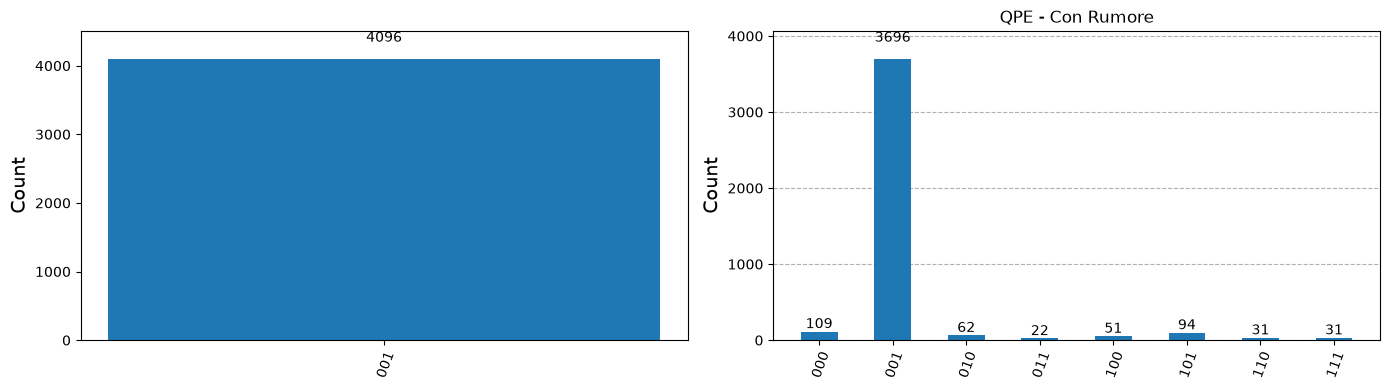

↑ left: the ideal single bar at 001; right: with noise the same mode, but part of the probability is scattered over the other seven bitstrings

Degradazione probabilità: 9.8%


In [17]:
# Confronto visivo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

plot_histogram(ideal_res['counts'], ax=ax1, title='QPE - Ideale')     # ax= draws into an existing panel instead of a new figure
plot_histogram(noisy_res['counts'], ax=ax2, title='QPE - Con Rumore')

plt.tight_layout()
plt.show()
print("↑ left: the ideal single bar at 001; right: with noise the same mode, but part of the probability is scattered over the other seven bitstrings")

print(f"\nDegradazione probabilità: {100*(ideal_prob - noisy_prob)/ideal_prob:.1f}%")   # relative loss of the mode's probability


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plot_histogram(counts, ax=ax1, ...)` | the histogram is drawn into a given matplotlib axis, which is how two histograms share one figure |
| `100*(ideal_prob - noisy_prob)/ideal_prob` | relative degradation of the mode's probability, in percent |

</details>


<a id='iqpe'></a>
## 6. 🔄 Iterative QPE (IQPE)

### 6.1 Motivazione

La QPE standard ha problemi su hardware NISQ:
- Richiede $n$ qubit ancilla simultaneamente entangled
- Circuiti molto profondi → più errori

**IQPE** risolve questi problemi usando:
- **1 solo qubit ancilla** (riusato)
- **Misure intermedie** + retroazione classica
- **Circuiti più corti** per ogni iterazione

### 6.2 Algoritmo

Estrae i bit della fase **uno alla volta**, dal meno significativo:

```
Per k = n-1, n-2, ..., 0:
    1. Reset ancilla → |0⟩
    2. Hadamard → |+⟩
    3. Controlled-U^(2^k)
    4. Correzione fase (basata sui bit già misurati)
    5. Hadamard + Misura → bit k
```

In [18]:
def build_iqpe_circuit(n_bits: int, phase_angle: float) -> QuantumCircuit:
    """
    Costruisce il circuito IQPE con dynamic circuits.

    Usa un solo qubit ancilla e misure intermedie con
    correzioni di fase condizionali.

    Args:
        n_bits: Numero di bit di precisione
        phase_angle: Angolo θ del gate P(θ)

    Returns:
        Circuito IQPE
    """
    ancilla = QuantumRegister(1, 'anc')                               # ONE counting qubit, reused n_bits times
    target = QuantumRegister(1, 'target')
    bits = ClassicalRegister(n_bits, 'bits')                          # bits[i] has weight 2^i in the result, like 'meas' in the QPE

    qc = QuantumCircuit(ancilla, target, bits)

    # Preparazione autostato |1⟩
    qc.x(target[0])

    # Iterazioni: dal bit MENO significativo (k = n-1, U^(2^(n-1))) al più significativo (k = 0)
    for k in range(n_bits - 1, -1, -1):                               # range(start, stop, step) counting down: n-1, n-2, ..., 0
        qc.barrier(label=f'Bit {k}')

        # 1. Reset e Hadamard
        qc.reset(ancilla)                                             # mid-circuit reset: the ancilla goes back to |0⟩ for the next bit
        qc.h(ancilla)

        # 2. Controlled-P^(2^k)
        angle = phase_angle * (2 ** k)
        qc.cp(angle, ancilla[0], target[0])                           # kicks the phase e^{2πi·2^k·φ} onto the |1⟩ component of the ancilla

        # 3. Correzione fase (dai bit già misurati, cioè quelli meno significativi)
        for j in range(k + 1, n_bits):
            correction = -np.pi / (2 ** (j - k))                      # remove the known contribution of the bit found at step j
            with qc.if_test((bits[n_bits - 1 - j], 1)):               # classical feed-forward: the block runs only if that classical bit == 1 (Qiskit 2.x replacement of the removed `gate.c_if`)
                qc.p(correction, ancilla)

        # 4. Hadamard + Misura -> cifra di peso 2^(n-1-k)
        qc.h(ancilla)
        qc.measure(ancilla, bits[n_bits - 1 - k])                     # mid-circuit measurement into classical bit n-1-k: step k = n-1 yields the least significant bit

    return qc


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `for k in range(n_bits - 1, -1, -1):` | k counts down: the first iteration applies U^(2^(n−1)) and learns the LEAST significant bit of φ; each later iteration learns the next one up |
| `qc.reset(ancilla)` / `qc.measure(ancilla, bits[...])` inside the loop | mid-circuit reset and measurement: the same physical qubit is measured n times — this is what makes it a *dynamic* circuit |
| `with qc.if_test((bits[i], 1)):` + body | a context manager that opens a classically-conditioned block: the gates inside run only if classical bit i reads 1. In Qiskit ≤ 1.x this was `qc.p(θ, anc).c_if(bits[i], 1)`; `c_if` was removed in Qiskit 2.0 |
| `bits[n_bits - 1 - j]`, `bits[n_bits - 1 - k]` | step k stores its digit in the classical bit of weight 2^(n−1−k), so that `int(bitstring, 2)/2ⁿ` decodes φ directly. The original indexed `bits[k]`, which wrote the digits in reverse order (the T gate read 100 instead of 001); the correction angles −π/2^(j−k) were already right |
| `-np.pi / 2 ** (j - k)` | the phase that the already-known lower bit (found at step j) contributes at this step: subtracting it leaves only ±π from the bit being measured, so H reads it with certainty |

</details>


In [19]:
# Costruisci IQPE per T-gate
n_bits_iqpe = 3
iqpe_circuit = build_iqpe_circuit(n_bits_iqpe, np.pi/4)               # 2 qubits (ancilla + target), 3 classical bits

print(f"Circuito IQPE per T-gate:")
print(f"  Bit di precisione: {n_bits_iqpe}")
print(f"  Qubit ancilla: 1 (vs {n_bits_iqpe} per QPE)")
print(f"  Profondità: {iqpe_circuit.depth()}")                       # deeper than the QPE (the bits are extracted in sequence) but on 2 qubits only
print(f"  Usa dynamic circuits: Sì")
print(f"  Istruzioni: {dict(iqpe_circuit.count_ops())}")              # 'if_else' = the conditional blocks, 'reset' and 'measure' inside the circuit


Circuito IQPE per T-gate:
  Bit di precisione: 3
  Qubit ancilla: 1 (vs 3 per QPE)
  Profondità: 19
  Usa dynamic circuits: Sì
  Istruzioni: {'h': 6, 'barrier': 3, 'reset': 3, 'cp': 3, 'measure': 3, 'if_else': 3, 'x': 1}


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `iqpe_circuit.depth()` | the price of reusing one ancilla: the three extractions happen one after the other, so the circuit is deeper than the parallel QPE |
| `count_ops()` with `if_else`, `reset`, `measure` | the dynamic-circuit instructions: conditional blocks, mid-circuit resets and measurements — a backend must support all three to run this circuit as is |

</details>


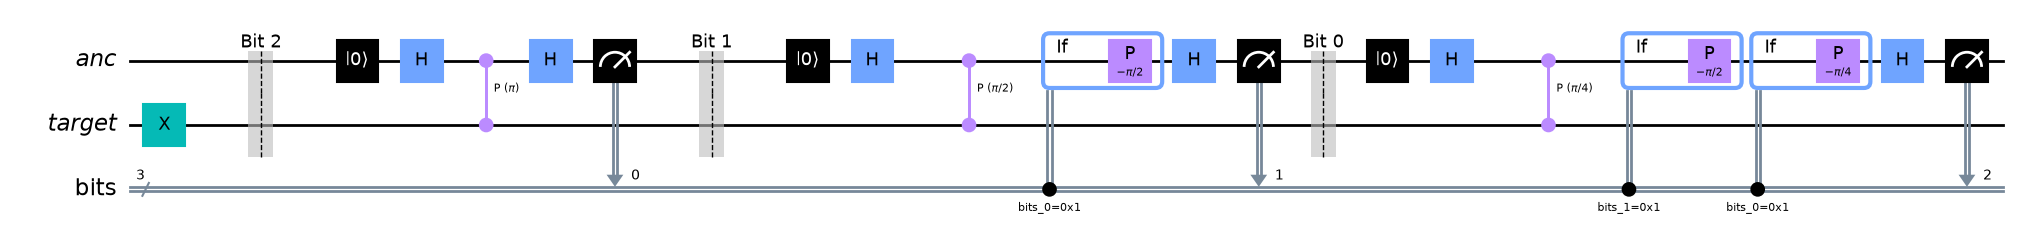

↑ IQPE for T with 3 bits: three blocks on the same ancilla — reset, H, CP(π/4·2^k), the phase corrections conditioned on the classical bits already measured (the 'if' boxes, with the double line from the classical register), H and a mid-circuit measurement


In [20]:
# Visualizza IQPE
display(draw(iqpe_circuit)); print("↑ IQPE for T with 3 bits: three blocks on the same ancilla — reset, H, CP(π/4·2^k), the phase corrections conditioned on the classical bits already measured (the 'if' boxes, with the double line from the classical register), H and a mid-circuit measurement")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| the three `Bit k` blocks | k = 2, 1, 0: the first block (U⁴) finds the least significant bit, the last (U¹) the most significant one, after correcting for the two already known |
| the boxes labelled `If` and the double lines | classical feed-forward in the drawing: a gate whose execution depends on a measured bit; the double line is the classical register |

</details>


In [21]:
def run_iqpe_simulation(circuit: QuantumCircuit, shots: int = 4096) -> dict:
    """Esegue IQPE (richiede supporto dynamic circuits)."""
    simulator = AerSimulator()                                        # Aer executes if_test / reset / mid-circuit measure natively
    sampler = AerSampler()

    job = sampler.run([circuit], shots=shots)                         # no transpilation needed: the circuit already uses gates Aer knows
    counts = job.result()[0].data.bits.get_counts()                   # the classical register is called 'bits' here (not 'meas')

    return {'counts': counts}

# Esegui IQPE
print("Esecuzione IQPE per T-gate...\n")
iqpe_results = run_iqpe_simulation(iqpe_circuit, shots=4096)
iqpe_phase, iqpe_prob = analyze_qpe_results(iqpe_results['counts'], n_bits_iqpe, true_phase=0.125)   # expected: 001 with probability 1


Esecuzione IQPE per T-gate...

════════════════════════════════════════════════════════════
ANALISI RISULTATI QPE
════════════════════════════════════════════════════════════

Binario      Decimale   Fase φ       Conteggi   Prob    
------------------------------------------------------------
001          1          0.125000     4096       1.0000   ← BEST

────────────────────────────────────────────────────────────
Fase stimata (modo): 0.125000
Fase vera: 0.125000
Errore assoluto: 0.000000
Errore relativo: 0.00%


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `AerSimulator()` + `AerSampler().run([circuit])` | dynamic circuits run on Aer as they are: conditional blocks, resets and mid-circuit measurements are simulated shot by shot |
| `.data.bits.get_counts()` | the counts are read under the register's name, `bits` — a different name from the QPE's `meas` |
| `001` with probability 1.0000 | the same answer as the QPE, obtained with one counting qubit: each bit comes out deterministic because the corrections cancel the lower bits exactly |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**IQPE bit by bit for $\varphi = 1/8 = 0.001_2$** ($\varphi_1\varphi_2\varphi_3 = 0\,0\,1$, from the most to the least significant). At each step the ancilla is $|+\rangle$, $CP$ adds the phase $2\pi\cdot 2^k\varphi$ to its $|1\rangle$ branch, the corrections subtract what is already known, and the final $H$ turns a phase of $0$ into $|0\rangle$ and a phase of $\pi$ into $|1\rangle$.

*Step $k = 2$ ($U^4$):* phase $2\pi \cdot 4/8 = \pi$. No corrections (nothing is known yet). $\tfrac{1}{\sqrt2}(|0\rangle + e^{i\pi}|1\rangle) = |-\rangle \xrightarrow{H} |1\rangle$: **bit 0 = 1** (the least significant digit, stored in `bits[0]`).

*Step $k = 1$ ($U^2$):* phase $2\pi\cdot 2/8 = \pi/2$. Correction from the bit found at $j = 2$: $-\pi/2^{\,2-1} = -\pi/2$, applied because that bit is $1$. Total $0$: $|+\rangle \xrightarrow{H} |0\rangle$: **bit 1 = 0**.

*Step $k = 0$ ($U^1$):* phase $2\pi/8 = \pi/4$. Corrections: from $j = 2$ (bit $1$): $-\pi/2^{2} = -\pi/4$; from $j = 1$ (bit $0$): nothing. Total $0 \to |0\rangle$: **bit 2 = 0**.

Reading the register with bit 2 as the most significant digit: $001_2 = 1$, $\hat\varphi = 1/8 = 0.125$ — every step was deterministic, so the cell above prints `001` with probability `1.0000` (ideal simulator). The rule behind it: after the corrections the ancilla phase is exactly $\pi\,\varphi_{n-k}$ when $\varphi$ has $n$ bits, i.e. $0$ or $\pi$ — the two states $H$ distinguishes perfectly. For a $\varphi$ that is not on the grid the leftover phase is in between, and each bit is read with probability $\cos^2(\text{leftover}/2)$: that is why the classical-feedback version below takes a majority vote over 1000 shots per bit.

</details>


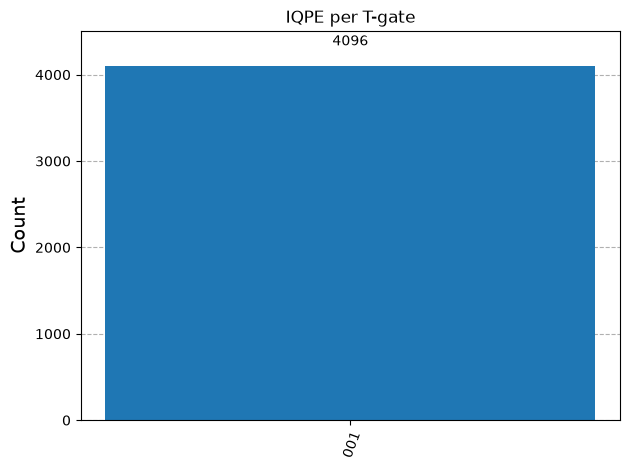

↑ the three bits read in sequence by a single ancilla give 001, the same answer as the 3-qubit QPE


In [22]:
display(plot_histogram(iqpe_results['counts'], title='IQPE per T-gate')); print("↑ the three bits read in sequence by a single ancilla give 001, the same answer as the 3-qubit QPE")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plot_histogram(iqpe_results['counts'])` | the bitstrings are the concatenation of the three mid-circuit measurements, bit 2 (most significant) first |
| one bar at 001 | every step is deterministic for a phase that is exact on the grid; compare with the spread of the φ = 1/3 QPE |

</details>


### 6.3 IQPE con Feedback Classico Esplicito

Per backend senza dynamic circuits, eseguiamo le iterazioni separatamente.

In [23]:
def run_iqpe_classical(n_bits: int, phase_angle: float,
                       shots_per_bit: int = 1000) -> dict:
    """
    IQPE con feedback classico esplicito.

    Esegue ogni iterazione separatamente, funziona su qualsiasi backend.

    Args:
        n_bits: Bit di precisione
        phase_angle: Angolo θ
        shots_per_bit: Shots per iterazione

    Returns:
        Fase stimata e statistiche
    """
    simulator = AerSimulator()                                        # one ideal simulator and Sampler for all the iterations
    sampler = AerSampler()

    measured_bits = []  # in the order found: least significant bit first (step k = n-1)
    bit_probs = []
    circuits = []                                                     # keep the per-bit circuits, to draw one afterwards

    print(f"{'Iter':<8} {'k':<5} {'Bit':<8} {'P(0)':<10} {'P(1)':<10}")
    print("-" * 45)

    for iteration, k in enumerate(range(n_bits - 1, -1, -1)):          # enumerate gives (0, n-1), (1, n-2), ...: iteration number AND k
        # Costruisci circuito per questa iterazione
        anc = QuantumRegister(1, 'anc')
        tgt = QuantumRegister(1, 'tgt')
        c = ClassicalRegister(1, 'c')                                 # a SINGLE classical bit: one fresh 2-qubit circuit per bit of φ
        qc = QuantumCircuit(anc, tgt, c)

        # Preparazione
        qc.x(tgt[0])  # |1⟩
        qc.h(anc)

        # Controlled-P^(2^k)
        qc.cp(phase_angle * (2**k), anc[0], tgt[0])

        # Correzione fase: the feedback is CLASSICAL — Python decides which P gates to add from the bits already measured
        for j, bit_val in enumerate(measured_bits):
            if bit_val == 1:                                          # only a measured 1 contributes a phase to remove
                bit_pos = n_bits - 1 - j                              # the k of the earlier iteration that produced this bit
                correction = -np.pi / (2 ** (bit_pos - k))            # same angle as in the dynamic circuit, now an ordinary (unconditional) gate
                qc.p(correction, anc)

        # Misura
        qc.h(anc)
        qc.measure(anc, c)
        circuits.append(qc)

        # Esegui
        pm = generate_preset_pass_manager(optimization_level=1, backend=simulator)
        transpiled = pm.run(qc)
        job = sampler.run([transpiled], shots=shots_per_bit)
        counts = job.result()[0].data.c.get_counts()                  # register 'c' -> {'0': n0, '1': n1}

        # Determina bit
        total = sum(counts.values())
        p0 = counts.get('0', 0) / total                               # dict.get(key, default): 0 if that outcome never appeared
        p1 = counts.get('1', 0) / total

        bit = 1 if p1 > p0 else 0                                     # majority vote over the shots: robust to a noisy minority
        measured_bits.append(bit)
        bit_probs.append(max(p0, p1))                                 # how clear-cut the vote was

        print(f"{iteration:<8} {k:<5} {bit:<8} {p0:<10.4f} {p1:<10.4f}")

    # Ricostruisci fase: measured_bits holds the LSB first, so reverse it to write the most significant digit first
    binary = ''.join(str(b) for b in reversed(measured_bits))         # generator expression inside join: list of ints -> '001'
    decimal = int(binary, 2)
    phase = decimal / (2 ** n_bits)

    print("-" * 45)
    print(f"Binario: {binary}")
    print(f"Fase: {phase:.6f}")
    print(f"Confidenza media: {np.mean(bit_probs):.4f}")

    return {'phase': phase, 'binary': binary, 'confidence': np.mean(bit_probs), 'circuits': circuits}


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `for iteration, k in enumerate(range(n_bits - 1, -1, -1))` | `enumerate` pairs a running index with each k: `iteration` numbers the rows of the table, `k` is the power of U |
| a fresh `QuantumCircuit(anc, tgt, c)` per iteration | no mid-circuit measurement and no `if_test`: every bit is a separate static circuit, so this version runs on ANY backend |
| `for j, bit_val in enumerate(measured_bits): if bit_val == 1: qc.p(correction, anc)` | the feedback happens in Python, between circuits: the corrections that the dynamic circuit applied with `if_test` are now plain gates, added only when the earlier bit was 1 |
| `counts.get('0', 0)`, `bit = 1 if p1 > p0 else 0` | majority vote over `shots_per_bit` shots; `.get(key, 0)` avoids a KeyError when an outcome never occurs |
| `''.join(str(b) for b in reversed(measured_bits))` | the bits were found least-significant first, so the list is reversed before being read as a binary number (the original joined them in the order found, printing 100 for 1/8) |
| `pm.run(qc)` → `sampler.run([transpiled], shots=shots_per_bit)` → `.data.c.get_counts()` | the usual Aer pipeline, three times; the register is called `c` here |

</details>


IQPE con Feedback Classico
Target: φ = 1/8 = 0.125

Iter     k     Bit      P(0)       P(1)      
---------------------------------------------


0        2     1        0.0000     1.0000    


1        1     0        1.0000     0.0000    


2        0     0        1.0000     0.0000    
---------------------------------------------
Binario: 001
Fase: 0.125000
Confidenza media: 1.0000

Errore: 0.000000


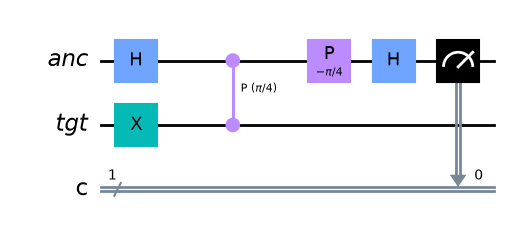

↑ the last iteration (k = 0): H on the ancilla, CP(π/4), then the correction −π/4 for the least significant bit already found (= 1), H and the measurement — an ordinary static circuit, the feedback happened in Python


In [24]:
# Test IQPE classico
print("IQPE con Feedback Classico")
print("=" * 45)
print(f"Target: φ = 1/8 = 0.125\n")

iqpe_classic = run_iqpe_classical(3, np.pi/4, shots_per_bit=1000)     # 3 separate circuits, 1000 shots each
print(f"\nErrore: {abs(iqpe_classic['phase'] - 0.125):.6f}")

display(draw(iqpe_classic['circuits'][-1])); print("↑ the last iteration (k = 0): H on the ancilla, CP(π/4), then the correction −π/4 for the least significant bit already found (= 1), H and the measurement — an ordinary static circuit, the feedback happened in Python")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| the table `Iter k Bit P(0) P(1)` | step by step: k = 2 reads 1 (P(1) ≈ 1), k = 1 and k = 0 read 0 — exactly the hand computation of the box above; `Binario: 001`, `Fase: 0.125` |
| `iqpe_classic['circuits'][-1]` | the circuit of the last iteration ([-1] = last element of the list): it contains the one correction gate that the earlier bit = 1 required |
| `Confidenza media` | the mean of the winning probabilities: 1.0 on the ideal simulator, lower on a noisy backend — a cheap quality indicator |

</details>


<a id='comparison'></a>
## 7. ⚖️ Confronto QPE vs IQPE

In [25]:
# Confronto risorse
print("═" * 70)
print("CONFRONTO RISORSE: QPE vs IQPE")
print("═" * 70)

data = []
for n in [3, 4, 5, 6]:
    qpe = build_qpe_circuit(n, np.pi/4)                               # n + 1 qubits
    iqpe = build_iqpe_circuit(n, np.pi/4)                             # always 2 qubits

    data.append({
        'n': n,
        'qpe_q': qpe.num_qubits,
        'iqpe_q': iqpe.num_qubits,
        'qpe_d': qpe.depth(),                                         # QPE depth grows linearly in n (one more CP in the kick-back and n more in QFT†)
        'iqpe_d': iqpe.depth(),                                       # IQPE depth grows faster: n sequential blocks, each with up to n−1 conditional corrections
    })

print(f"\n{'Bit':<6} {'QPE Qubit':<12} {'IQPE Qubit':<12} {'QPE Depth':<12} {'IQPE Depth':<12}")
print("-" * 55)
for d in data:
    print(f"{d['n']:<6} {d['qpe_q']:<12} {d['iqpe_q']:<12} {d['qpe_d']:<12} {d['iqpe_d']:<12}")


══════════════════════════════════════════════════════════════════════
CONFRONTO RISORSE: QPE vs IQPE
══════════════════════════════════════════════════════════════════════

Bit    QPE Qubit    IQPE Qubit   QPE Depth    IQPE Depth  
-------------------------------------------------------
3      4            2            12           19          
4      5            2            15           27          
5      6            2            18           36          
6      7            2            21           46          


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qpe.num_qubits` vs `iqpe.num_qubits` | n+1 against 2: the whole point of IQPE on a small device |
| `qpe.depth()` vs `iqpe.depth()` | the trade-off: the single ancilla must work n times in a row, so the IQPE circuit is deeper (though each block is short and the `if_test` blocks count as one layer each) |
| `data.append({...})` / `for d in data:` | again a list of dicts as a small table, printed row by row with aligned f-string columns |

</details>


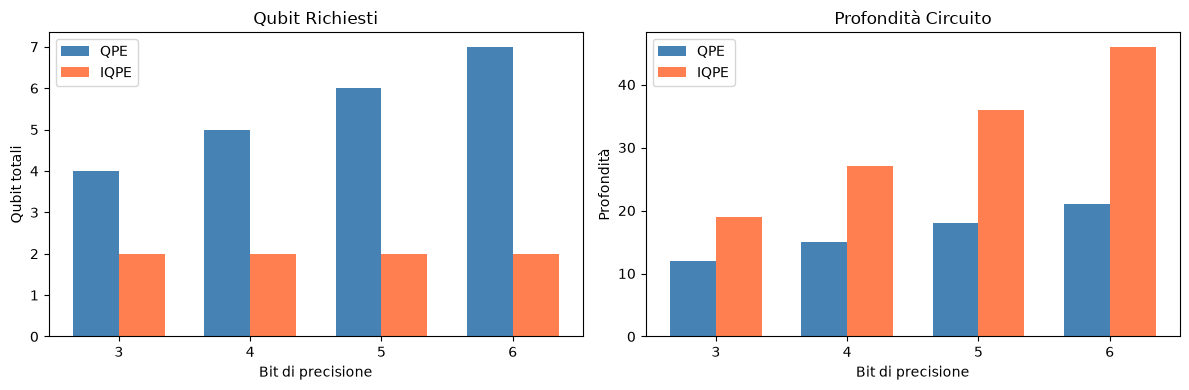

↑ left: QPE needs n+1 qubits, IQPE always 2; right: the price is depth — the IQPE circuit is deeper and grows faster with n


In [26]:
# Grafico comparativo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ns = [d['n'] for d in data]
x = np.arange(len(ns))                                                # bar positions 0, 1, 2, 3
w = 0.35                                                              # bar width: two bars per position, shifted by ±w/2

ax1.bar(x - w/2, [d['qpe_q'] for d in data], w, label='QPE', color='steelblue')
ax1.bar(x + w/2, [d['iqpe_q'] for d in data], w, label='IQPE', color='coral')
ax1.set_xlabel('Bit di precisione')
ax1.set_ylabel('Qubit totali')
ax1.set_title('Qubit Richiesti')
ax1.set_xticks(x)                                                     # ticks at the bar positions ...
ax1.set_xticklabels(ns)                                               # ... labelled with the number of bits
ax1.legend()

ax2.bar(x - w/2, [d['qpe_d'] for d in data], w, label='QPE', color='steelblue')
ax2.bar(x + w/2, [d['iqpe_d'] for d in data], w, label='IQPE', color='coral')
ax2.set_xlabel('Bit di precisione')
ax2.set_ylabel('Profondità')
ax2.set_title('Profondità Circuito')
ax2.set_xticks(x)
ax2.set_xticklabels(ns)
ax2.legend()

plt.tight_layout()
plt.show()
print("↑ left: QPE needs n+1 qubits, IQPE always 2; right: the price is depth — the IQPE circuit is deeper and grows faster with n")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `ax.bar(x - w/2, ..., w)` / `ax.bar(x + w/2, ..., w)` | grouped bars: the two series are shifted left and right of each tick by half a bar width |
| `set_xticks(x)` + `set_xticklabels(ns)` | replace the positions 0..3 by the meaningful labels 3..6 bits |

</details>


### Riepilogo Vantaggi/Svantaggi

| Aspetto | QPE Standard | IQPE |
|---------|--------------|------|
| Qubit ancilla | n | 1 |
| Profondità | Alta | Media |
| Misure | 1 finale | n intermedie |
| Dynamic circuits | No | Sì |
| Robustezza rumore | Bassa | Migliore |
| Parallelismo | Alto | Sequenziale |

<a id='errors'></a>
## 8. 📊 Analisi degli Errori

In [27]:
print("═" * 65)
print("FONTI DI ERRORE IN QPE")
print("═" * 65)
print("""
1. DISCRETIZZAZIONE (intrinseco)
   Errore: Δφ = 1/2^(n+1)
   Soluzione: aumentare n

2. DECOERENZA (hardware)
   Causa: T1, T2 finiti
   Soluzione: circuiti corti, IQPE

3. ERRORI DI GATE (hardware)
   Gate 2q più rumorosi (~1% vs ~0.1%)
   Soluzione: ottimizzazione, error mitigation

4. ERRORI DI MISURA (hardware)
   Tipicamente 1-5%
   Soluzione: readout error mitigation
""")                                                                  # a triple-quoted string keeps its line breaks: a multi-line print in one call


═════════════════════════════════════════════════════════════════
FONTI DI ERRORE IN QPE
═════════════════════════════════════════════════════════════════

1. DISCRETIZZAZIONE (intrinseco)
   Errore: Δφ = 1/2^(n+1)
   Soluzione: aumentare n

2. DECOERENZA (hardware)
   Causa: T1, T2 finiti
   Soluzione: circuiti corti, IQPE

3. ERRORI DI GATE (hardware)
   Gate 2q più rumorosi (~1% vs ~0.1%)
   Soluzione: ottimizzazione, error mitigation

4. ERRORI DI MISURA (hardware)
   Tipicamente 1-5%
   Soluzione: readout error mitigation



<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `print(""" ... """)` | triple quotes = a multi-line string literal; the only Python here |
| 1/2^(n+1) vs the other three | only the first error shrinks by adding qubits; the other three GROW with the circuit, which is the tension explored in the next cell |

</details>


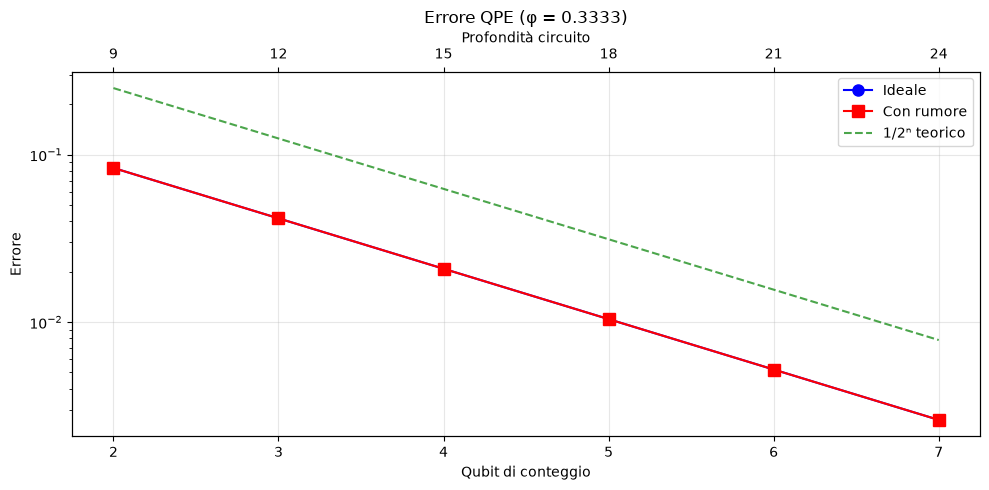

↑ the error of the mode vs the number of counting qubits (bottom axis) and the circuit depth (top axis): ideal (blue) and with the noise model (red) against the resolution 1/2ⁿ (green); where the red curve leaves the blue one, noise has moved the mode off the nearest grid point

Osservazione: con rumore, oltre un certo punto aumentare n peggiora!


In [28]:
# Errore vs profondità con rumore
phi_true = 1/3
theta = 2 * np.pi * phi_true
noise = create_noise_model(p1q=0.0005, p2q=0.005)                     # a gentler noise model than in Section 5.1 (half the error rates)

ideal_errors = []
noisy_errors = []
depths = []

for n in range(2, 8):                                                 # 2 ... 7 counting qubits
    qpe = build_qpe_circuit(n, theta)
    depths.append(qpe.depth())

    # Ideale
    res_i = run_qpe_simulation(qpe, shots=2048)
    top_i = max(res_i['counts'].items(), key=lambda x: x[1])          # the mode
    ph_i = int(top_i[0], 2) / (2**n)
    ideal_errors.append(abs(ph_i - phi_true))

    # Rumoroso
    res_n = run_qpe_noisy(qpe, noise, shots=2048)
    top_n = max(res_n['counts'].items(), key=lambda x: x[1])
    ph_n = int(top_n[0], 2) / (2**n)
    noisy_errors.append(abs(ph_n - phi_true))                         # if noise moves the mode to a wrong bitstring, this jumps

# Plot
fig, ax = plt.subplots(figsize=(10, 5))

ns = list(range(2, 8))
ax.semilogy(ns, ideal_errors, 'bo-', label='Ideale', ms=8)
ax.semilogy(ns, noisy_errors, 'rs-', label='Con rumore', ms=8)
ax.semilogy(ns, [1/(2**n) for n in ns], 'g--', label='1/2ⁿ teorico', alpha=0.7)

ax.set_xlabel('Qubit di conteggio')
ax.set_ylabel('Errore')
ax.set_title(f'Errore QPE (φ = {phi_true:.4f})')
ax.legend()
ax.grid(True, alpha=0.3)

ax2 = ax.twiny()                                                      # a second x axis on top, sharing the plot ...
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks(ns)
ax2.set_xticklabels(depths)                                           # ... labelled with the circuit depth of each n
ax2.set_xlabel('Profondità circuito')

plt.tight_layout()
plt.show()
print("↑ the error of the mode vs the number of counting qubits (bottom axis) and the circuit depth (top axis): ideal (blue) and with the noise model (red) against the resolution 1/2ⁿ (green); where the red curve leaves the blue one, noise has moved the mode off the nearest grid point")

print("\nOsservazione: con rumore, oltre un certo punto aumentare n peggiora!")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `create_noise_model(p1q=0.0005, p2q=0.005)` | a milder noise model, so the cross-over between resolution gain and noise loss is visible within n ≤ 7 |
| the loop over `n` with `run_qpe_simulation` and `run_qpe_noisy` | the same circuit on the ideal and the noisy simulator at each size; `depths` records how the circuit grows |
| `ax.twiny()` | a twin x axis on top: the same points labelled by circuit depth instead of qubit count — the quantity the noise actually cares about |
| the printed observation | the physics lesson: discretisation error falls like 1/2ⁿ, but the circuit depth grows linearly in n and each extra layer costs fidelity; past some n the mode is no longer the nearest value (with this mild model the effect may show only for the largest n, or not at all in a given run — the counts are random) |

</details>


<a id='exercises'></a>
## 9. 🎓 Esercizi

### Esercizio 1: S-gate (Facile)
Stima la fase dell'S-gate ($\theta = \pi/2$, $\varphi = 1/4$).

### Esercizio 2: Precisione (Medio)
Quanti qubit servono per stimare $\varphi = \sqrt{2}/4$ con errore < 0.01?

### Esercizio 3: Robustezza (Avanzato)
Confronta QPE e IQPE variando il rumore. Trova il crossover point.

In [29]:
# Spazio esercizi                                                      # the author's exercise area: keep your attempts here

# Es 1: S-gate
# qpe_s = build_qpe_circuit(3, np.pi/2)
# ...

# Es 2: sqrt(2)/4
# phi = np.sqrt(2)/4
# ...


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| commented-out lines | the author's exercise area: uncomment and complete them; the In-depth analysis below solves Exercises 1 and 2 as reference |
| `build_qpe_circuit(3, np.pi/2)` | the S gate has phase π/2 = 2π·(1/4): with 3 counting qubits the register should read 010 exactly |

</details>


## 🔬 In-depth analysis

1. **The S gate (the author's Exercise 1).** Run the 3-qubit QPE with $\theta = \pi/2$. Which bitstring is the mode, what phase does it decode to, and why is the result exact?
2. **Qubits for a precision (the author's Exercise 2).** For $\varphi = \sqrt2/4 \approx 0.35355$, use the box of Section 4.3 to find the number of counting qubits $t$ whose resolution $1/2^t$ is below $0.01$, run the QPE with that $t$ and check that $|\hat\varphi - \varphi| < 1/2^t$ (ideally $< 1/2^{t+1}$).
3. **A superposition of eigenstates.** Build the T-gate QPE with `prepare_eigenstate=False` and put the target in $|+\rangle = (|0\rangle + |1\rangle)/\sqrt2$ before the controlled phases (compose an $H$ in front of the circuit). Which outcomes appear, and with which weights? Relate them to the two eigenphases of $T$ ($0$ for $|0\rangle$, $1/8$ for $|1\rangle$) and to $|\langle\psi|u_j\rangle|^2$.

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [30]:
# 🔬 In-depth analysis — your code here



(1) S gate: mode 010 -> φ̂ = 0.2500 (expected 1/4 = 0.25), P(mode) = 1.000: 2^3 · 1/4 = 2 is an integer, so the state before QFT† is exactly QFT|2⟩


(2) φ = √2/4 = 0.35355: t = 7 counting qubits (resolution 1/2^t = 0.00781); mode 0101101 -> φ̂ = 0.35156, |φ̂ − φ| = 0.00199 < 1/2^t
(3) target |+⟩: P(000) = 0.493 (eigenphase 0 of |0⟩), P(001) = 0.507 (eigenphase 1/8 of |1⟩), other outcomes 0.000: QPE does not average the phases, it samples one eigenvalue per shot


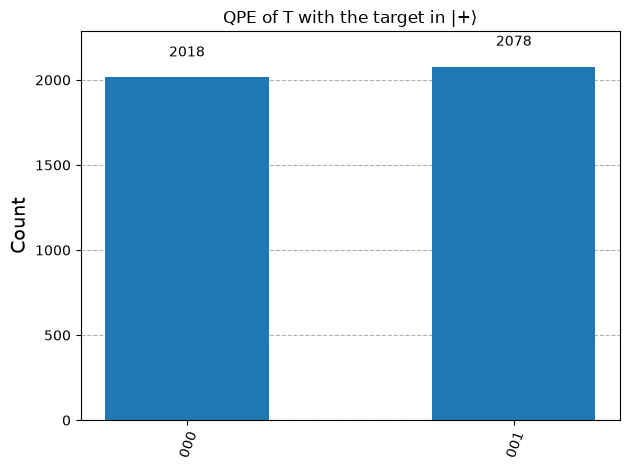

↑ two bars of (ideally) equal height: each shot collapses the target onto one eigenvector of T and reports that eigenvector's phase


In [31]:
# Reference solution
# (1) S gate: θ = π/2 -> φ = 1/4 = 0.010₂, exact with 3 bits (the author's Exercise 1)
res_s = run_qpe_simulation(build_qpe_circuit(3, np.pi / 2), shots=4096)
mode_s, n_s = max(res_s['counts'].items(), key=lambda kv: kv[1])          # the (bitstring, count) pair with the largest count
print(f"(1) S gate: mode {mode_s} -> φ̂ = {int(mode_s, 2) / 8:.4f} (expected 1/4 = 0.25), P(mode) = {n_s / 4096:.3f}: "
      f"2^3 · 1/4 = 2 is an integer, so the state before QFT† is exactly QFT|2⟩")

# (2) qubits for a precision: resolution 1/2^t < 0.01 -> t = ceil(log2(100)) = 7 (the author's Exercise 2)
phi_sq = np.sqrt(2) / 4
t_bits = int(np.ceil(np.log2(1 / 0.01)))                                  # smallest t with 2^-t < 0.01
res_sq = run_qpe_simulation(build_qpe_circuit(t_bits, 2 * np.pi * phi_sq), shots=4096)
mode_sq = max(res_sq['counts'].items(), key=lambda kv: kv[1])[0]          # [0] = the bitstring of the mode
phi_hat = int(mode_sq, 2) / 2 ** t_bits
print(f"(2) φ = √2/4 = {phi_sq:.5f}: t = {t_bits} counting qubits (resolution 1/2^t = {2 ** -t_bits:.5f}); "
      f"mode {mode_sq} -> φ̂ = {phi_hat:.5f}, |φ̂ − φ| = {abs(phi_hat - phi_sq):.5f} "
      f"{'<' if abs(phi_hat - phi_sq) < 2 ** -t_bits else '>='} 1/2^t")

# (3) target in |+⟩ = (|0⟩ + |1⟩)/√2: QPE returns each eigenphase with probability |<ψ|u_j>|² = 1/2
qc_plus = build_qpe_circuit(3, np.pi / 4, prepare_eigenstate=False)      # the target is left in |0⟩ ...
prep = QuantumCircuit(*qc_plus.qregs, *qc_plus.cregs)                     # an empty circuit on the same registers (* unpacks the register lists)
prep.h(qc_plus.qregs[1][0])                                               # ... H on the target qubit (register 1 = 'target') -> |+⟩
qc_plus = prep.compose(qc_plus)                                           # prep first, then the whole QPE
res_plus = run_qpe_simulation(qc_plus, shots=4096)
p = {k: v / 4096 for k, v in res_plus['counts'].items()}                  # dict comprehension: counts -> probabilities
print(f"(3) target |+⟩: P(000) = {p.get('000', 0):.3f} (eigenphase 0 of |0⟩), P(001) = {p.get('001', 0):.3f} (eigenphase 1/8 of |1⟩), "
      f"other outcomes {1 - p.get('000', 0) - p.get('001', 0):.3f}: QPE does not average the phases, it samples one eigenvalue per shot")
display(plot_histogram(res_plus['counts'], title='QPE of T with the target in |+⟩')); print("↑ two bars of (ideally) equal height: each shot collapses the target onto one eigenvector of T and reports that eigenvector's phase")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `max(counts.items(), key=lambda kv: kv[1])` | the mode of a histogram in one line; unpacked into `(bitstring, count)` or indexed with `[0]` for the bitstring only |
| `int(np.ceil(np.log2(1 / 0.01)))` | the box of Section 4.3 in code: the smallest t with 1/2^t below the wanted precision (7 → resolution 0.0078) |
| `'<' if cond else '>='` inside an f-string | a conditional expression can live inside the braces of an f-string |
| `QuantumCircuit(*qc.qregs, *qc.cregs)` + `prep.compose(qc)` | an empty circuit over the SAME registers (the `*` unpacks the lists) can be composed in front of an existing one: here it prepares \|+⟩ on the target before the QPE |
| `{k: v / 4096 for k, v in counts.items()}` | dict comprehension: the same keys, each value divided by the shots → probabilities |
| P(000) ≈ P(001) ≈ 1/2 | the postulate at work: an input Σ_j c_j \|u_j⟩ gives eigenphase φ_j with probability \|c_j\|²; QPE on a superposition is a measurement in the eigenbasis of U, not a phase average |

</details>


<a id='references'></a>
## 10. 📖 Riferimenti

1. **Kitaev** (1995). *Quantum measurements and the Abelian Stabilizer Problem*. arXiv:quant-ph/9511026

2. **Nielsen & Chuang** (2000). *Quantum Computation and Quantum Information*. Section 5.2

3. **Dobšíček et al.** (2007). *Arbitrary accuracy iterative QPE*. Phys. Rev. A 76, 030306(R)

4. [Qiskit Textbook - QPE](https://learn.qiskit.org/course/ch-algorithms/quantum-phase-estimation)

---

**Course**: Quantum Computing Laboratory  
**License**: MIT  
**Version**: 2.2.0 (con Gate Parametrici Nativi + IQPE)  
**Last Updated**: December 2025